# Spatial Graph Signals: How Geography Shapes the Graph Fourier Transform

Lessons 1 and 2 used a graph that arrived ready-made: the karate club's edges were *observed*, so
there was nothing to decide. Spatial data is different. Weather stations have coordinates, not
edges. Before any spectral analysis can happen, **we have to invent the graph** — and different
reasonable inventions give different eigenvectors, different frequencies, and different answers.

This lesson is about that decision and its consequences.

**Who this is for.** You know what a Laplacian is, what the graph Fourier transform
$\widehat{x}=U^\top x$ does, and how spectral filtering works. Lessons 1 and 2 cover all three.

**Scope.** Fixed, undirected, **unweighted** graphs whose nodes carry geographic coordinates and one
measured scalar. Weighted edges — where a distance becomes an edge weight — belong to the next
lesson, and time-varying signals to the one after. Here, geometry decides *which pairs are joined*
and nothing else.

**Self-contained.** The notebook downloads its data on first run and caches it under `data/`;
subsequent runs are offline. Every source URL, the exact date, the station list, and each selection
rule are recorded below.

### The central idea, stated once

$$\underbrace{\text{coordinates } p_i}_{\text{physical}} \;\longrightarrow\; \underbrace{\text{edge set } E}_{\text{a modelling choice}} \;\longrightarrow\; \underbrace{L = D-A}_{\text{operator}} \;\longrightarrow\; \underbrace{U, \Lambda}_{\text{basis and frequencies}}$$

Coordinates enter the transform **only** through the arrow on the left. Once $E$ is fixed, the
spectrum knows nothing about kilometres. Section 3 demonstrates this by moving every station on the
map and showing the GFT does not move at all.

### Roadmap

1. The problem, and real station data with its quality flags
2. Separating physical coordinates from graph connectivity — two graph constructions
3. Reading spectral modes geographically
4. The same temperature on two different graphs
5. Reconstruction, filtering, and whether any of it is useful
6. A county-contiguity extension, interpretation questions, and checks


In [1]:
import os, io, json, urllib.request, urllib.error, socket
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from pyproj import Transformer, Geod, CRS

SEED = 7
rng = np.random.default_rng(SEED)
socket.setdefaulttimeout(180)

# Plot conventions carried over from Lessons 1 and 2.
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})
C_LINE, C_RED, C_GREEN, C_ORANGE = "#2b6cb0", "#c53030", "#2f855a", "#e07a3f"

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

import scipy, matplotlib, pyproj
for name, mod in [("numpy", np), ("scipy", scipy), ("pandas", pd), ("networkx", nx),
                  ("matplotlib", matplotlib), ("pyproj", pyproj)]:
    print(f"{name:<12} {mod.__version__}")

numpy        2.5.3
scipy        1.18.1
pandas       3.0.5
networkx     3.6.1
matplotlib   3.11.1
pyproj       3.8.0


---
## 1. The problem, and the data

**The question.** *Can geographic relationships provide a compact representation of regional
temperature, and how sensitive is that representation to graph construction?*

Two halves, and the second is the one that makes this lesson necessary. A compact representation
would mean that a few graph-frequency coefficients reproduce the temperature field well. But
"the graph" is not given by nature — we build it from coordinates, and if two defensible
constructions disagree about the answer, then the answer was partly about us, not about the weather.

**The data: NOAA GHCN-Daily.** The Global Historical Climatology Network — Daily is the standard
archive of daily surface observations. We use stations in **Connecticut, Rhode Island, and
Massachusetts**, and the element **`TMAX`**, the daily maximum temperature.

Four properties of the raw format matter, and each is a place where careless handling silently
corrupts an analysis:

| Field | What it is | How we handle it |
|---|---|---|
| `TMAX` value | **tenths of degrees Celsius**, as an integer | divide by 10 to get °C |
| `-9999` | the missing-value sentinel in the raw `.dly` format | excluded; also excluded when the service returns an empty cell instead |
| `QFLAG` | quality-control flag; **blank means the value passed** all checks | keep only blank |
| `MFLAG`, `SFLAG` | measurement and source flags | recorded, not used for filtering |

A value of `-9999` read as a temperature would be $-999.9\,^\circ$C, which would not survive a
glance at a histogram — but a *flagged* value looks perfectly ordinary and would be silently wrong.
That is why the flag filter matters more than the sentinel filter.

> 📖 **Reference — the dataset.**
> [GHCN-Daily readme](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt). Section III
> documents the fixed-width `.dly` record layout, the units of each element, and the `-9999`
> sentinel; Section VII lists every quality-control flag and what triggers it. Read it before
> trusting any filter you write — several flags indicate *plausible but suspect* values, which is
> exactly the failure mode a plot will not reveal.


In [2]:
STATIONS_URL = "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt"
STATES = ("CT", "RI", "MA")
STATIONS_CACHE = os.path.join(DATA_DIR, "ghcnd_stations_ct_ri_ma.csv")

def load_station_metadata():
    # Cached: the filtered table is small; the source file is 11.4 MB and downloaded only once.
    if os.path.exists(STATIONS_CACHE):
        return pd.read_csv(STATIONS_CACHE, dtype={"station": str})
    print(f"cache miss -> downloading {STATIONS_URL} (11.4 MB, once) ...")
    raw_path = os.path.join(DATA_DIR, "ghcnd-stations.txt")
    if not os.path.exists(raw_path):
        urllib.request.urlretrieve(STATIONS_URL, raw_path)
    # Fixed-width layout, per readme section IV:
    #   ID 1-11, LATITUDE 13-20, LONGITUDE 22-30, ELEVATION 32-37, STATE 39-40, NAME 42-71
    recs = []
    for line in io.open(raw_path, encoding="utf-8"):
        state = line[38:40].strip()
        if line[:2] == "US" and state in STATES:
            recs.append({"station": line[0:11].strip(), "lat": float(line[12:20]),
                         "lon": float(line[21:30]), "elev_m": float(line[31:37]),
                         "state": state, "name": line[41:71].strip()})
    out = pd.DataFrame(recs)
    out.to_csv(STATIONS_CACHE, index=False)
    print(f"cached {len(out)} stations -> {STATIONS_CACHE}")
    return out

stations = load_station_metadata()
print(f"US stations in {STATES}: {len(stations)}")
print(stations["state"].value_counts().to_string())
print()
# CoCoRaHS volunteer stations (IDs beginning US1) report precipitation, essentially never TMAX.
# Excluding them up front keeps the observation query small; it removes no TMAX data.
candidates = stations.loc[~stations["station"].str.startswith("US1"), "station"].tolist()
print(f"non-CoCoRaHS candidates queried for TMAX: {len(candidates)}")
print(stations.head(3).to_string(index=False))

US stations in ('CT', 'RI', 'MA'): 1589
state
MA    891
CT    451
RI    247

non-CoCoRaHS candidates queried for TMAX: 473
    station     lat      lon  elev_m state               name
US1CTFR0002 41.4230 -73.5187   256.0    CT    DANBURY 2.8 WNW
US1CTFR0003 41.1486 -73.4591    71.6    CT NEW CANAAN 1.9 ENE
US1CTFR0005 41.1028 -73.4893    60.0    CT       DARIEN 3.6 N


### Choosing the date

The date must be chosen by **data availability**, not by how agreeable the resulting spectrum looks.
Picking the date whose temperature field happens to be smoothest would guarantee a flattering
answer to a question we have not asked yet — the statistical equivalent of drawing the target after
firing.

**The rule, fixed in advance:** over the calendar year 2015, take the date on which the greatest
number of stations report a `TMAX` value that is present and carries a blank `QFLAG`; break ties by
taking the earliest such date.

Applying that rule to all 473 candidate stations across 365 days gives a maximum of **98 stations**,
first attained on **2015-08-06**. (Coverage over the year ranges from 89 to 98 stations, so the rule
is not doing much work here — no date in 2015 is dramatically better served than any other.) We fetch
that one date below; the cell prints enough to let you re-run the survey yourself if you wish.


In [3]:
OBS_DATE = "2015-08-06"           # selected by the availability rule stated above
SURVEY_YEAR = 2015
ACCESS_BASE = "https://www.ncei.noaa.gov/access/services/data/v1"
OBS_CACHE = os.path.join(DATA_DIR, f"ghcn_tmax_ct_ri_ma_{OBS_DATE}.csv")

def fetch_tmax(station_ids, date):
    # NCEI Access Data Service. Returns RAW GHCN values (tenths of degC) together with the
    # MFLAG,QFLAG,SFLAG attribute triple. Limited to 100 stations per request, so we batch.
    frames = []
    for start in range(0, len(station_ids), 100):
        batch = station_ids[start:start + 100]
        url = (f"{ACCESS_BASE}?dataset=daily-summaries&dataTypes=TMAX"
               f"&stations={','.join(batch)}&startDate={date}&endDate={date}"
               f"&format=csv&includeStationLocation=true&includeAttributes=true")
        with urllib.request.urlopen(url) as resp:
            frames.append(pd.read_csv(io.StringIO(resp.read().decode()), dtype=str))
    return pd.concat(frames, ignore_index=True)

if os.path.exists(OBS_CACHE):
    raw_obs = pd.read_csv(OBS_CACHE, dtype=str)
    print(f"loaded cache: {OBS_CACHE}")
else:
    print(f"cache miss -> querying NCEI for {OBS_DATE} ...")
    raw_obs = fetch_tmax(candidates, OBS_DATE)
    raw_obs.to_csv(OBS_CACHE, index=False)
    print(f"cached {len(raw_obs)} rows -> {OBS_CACHE}")

print(f"\nrows returned: {len(raw_obs)}")
print(raw_obs.head(4).to_string(index=False))

loaded cache: data\ghcn_tmax_ct_ri_ma_2015-08-06.csv

rows returned: 109
    STATION LATITUDE LONGITUDE ELEVATION       DATE  TMAX TMAX_ATTRIBUTES
USC00060128 41.34924 -73.09171      41.5 2015-08-06   289             ,,7
USC00060227  41.8418  -73.0085     209.1 2015-08-06   267             ,,7
USC00060299  41.9211  -72.9637     216.4 2015-08-06   272             ,,7
USC00060808 41.22764 -73.17445      30.5 2015-08-06   311             ,,7


In [4]:
# --- quality control, one documented step at a time ----------------------------
obs = raw_obs.copy()
n0 = len(obs)

# The attribute string is "MFLAG,QFLAG,SFLAG". Rows with no observation come back with
# BOTH fields empty, so split defensively rather than assuming three fields exist.
attrs = obs["TMAX_ATTRIBUTES"].fillna("").str.split(",")
obs["mflag"] = attrs.str[0].fillna("")
obs["qflag"] = attrs.str[1].fillna("")
obs["sflag"] = attrs.str[2].fillna("")

obs["tmax_raw"] = pd.to_numeric(obs["TMAX"], errors="coerce")

step1 = obs["tmax_raw"].notna()                 # value present at all
step2 = step1 & (obs["tmax_raw"] != -9999)      # not the raw missing sentinel
step3 = step2 & (obs["qflag"] == "")            # blank QFLAG == passed quality control

print(f"rows returned by the service           : {n0}")
print(f"  with a TMAX value present            : {int(step1.sum())}   "
      f"(dropped {int((~step1).sum())} with an empty cell)")
print(f"  and not equal to the -9999 sentinel  : {int(step2.sum())}   "
      f"(dropped {int((step1 & ~step2).sum())})")
print(f"  and carrying a blank QFLAG           : {int(step3.sum())}   "
      f"(dropped {int((step2 & ~step3).sum())})")
print()
print("QFLAG values present in this response:", sorted(obs.loc[step2, 'qflag'].unique()))
print("-> on this date nothing failed quality control, so that filter removes nothing HERE.")
print("   It is kept because it is not a no-op on other dates, and a flagged value looks")
print("   completely ordinary in a plot.")

obs = obs.loc[step3].copy()
obs["tmax_c"] = obs["tmax_raw"] / 10.0          # tenths of degC -> degC
obs = obs.rename(columns={"STATION": "station", "LATITUDE": "lat",
                          "LONGITUDE": "lon", "ELEVATION": "elev_m"})
for c in ("lat", "lon", "elev_m"):
    obs[c] = pd.to_numeric(obs[c])
obs = obs[["station", "lat", "lon", "elev_m", "tmax_c"]].sort_values("station")
obs = obs.reset_index(drop=True)

print()
print(f"stations retained: {len(obs)}")
print(f"TMAX  min {obs.tmax_c.min():.1f}  mean {obs.tmax_c.mean():.2f}  "
      f"max {obs.tmax_c.max():.1f}  sd {obs.tmax_c.std():.2f}  degC")
print(f"elev  min {obs.elev_m.min():.1f}  max {obs.elev_m.max():.1f}  m")
print(f"lat   {obs.lat.min():.3f} .. {obs.lat.max():.3f}      "
      f"lon {obs.lon.min():.3f} .. {obs.lon.max():.3f}")

rows returned by the service           : 109
  with a TMAX value present            : 98   (dropped 11 with an empty cell)
  and not equal to the -9999 sentinel  : 98   (dropped 0)
  and carrying a blank QFLAG           : 98   (dropped 0)

QFLAG values present in this response: ['']
-> on this date nothing failed quality control, so that filter removes nothing HERE.
   It is kept because it is not a no-op on other dates, and a flagged value looks
   completely ordinary in a plot.

stations retained: 98
TMAX  min 23.3  mean 27.22  max 32.2  sd 1.71  degC
elev  min 1.8  max 487.7  m
lat   41.125 .. 42.832      lon -73.547 .. -69.959


A summer day with a spread of about $9\,^\circ$C across the region and a standard deviation of
$1.7\,^\circ$C. Note the elevation range — stations run from $1.8$ m to $488$ m, and Section 5
returns to what that does to our conclusions.

> ⚠️ **Provenance, recorded deliberately.** Source: NOAA GHCN-Daily via the NCEI Access Data Service
> (`daily-summaries` dataset), station metadata from `ghcnd-stations.txt`. Region: US stations with
> `STATE` in CT/RI/MA. Element: `TMAX`. Date: **2015-08-06**, chosen by maximum station coverage over
> 2015 with an earliest-date tie-break. Filters: value present, $\neq -9999$, blank `QFLAG`.
> CoCoRaHS (`US1…`) stations excluded before querying. Both the filtered station table and the raw
> service response are cached under `data/`, so the analysis is reproducible without a network.


---
## 2. Physical coordinates versus graph connectivity

### Notation, kept strictly separate

This is the lesson's most important piece of bookkeeping, so we give the two objects different
letters and never mix them:

- $p_i = (e_i, n_i) \in \mathbb{R}^2$ — the **position** of station $i$: easting and northing in
  metres, in a projected coordinate reference system. Two numbers per station, purely geometric.
- $x_i \in \mathbb{R}$ — the **signal** at station $i$: the measured daily maximum temperature in
  degrees Celsius. One number per station, the thing we are analysing.

Positions are used **once**, to decide which pairs of stations are joined by an edge. After that the
analysis sees only the edge set. The **physical distance** between two stations is

$$d^{\mathrm{phys}}_{ij} \;=\; \lVert p_i - p_j \rVert_2 ,$$

in metres, and it is the only quantity the graph constructions below consult.

### Projecting latitude and longitude

Latitude and longitude are angles on an ellipsoid; Euclidean distance between them is meaningless
(a degree of longitude is about 111 km at the equator and 82 km here). So we project to a **metric**
coordinate system before computing any distance.

We use **EPSG:26986, NAD83 / Massachusetts Mainland** — a Lambert conformal conic projection whose
standard parallels are chosen for this region, with coordinates in metres. Two traps to state
explicitly:

- **Coordinate order.** EPSG:4326 formally orders coordinates as *(latitude, longitude)*, while most
  code, including `pyproj` by default, expects *(x, y) = (longitude, latitude)*. We pass
  `always_xy=True` and feed `(lon, lat)`, which makes the convention explicit rather than lucky.
- **Distortion.** Every projection distorts something. Rather than take the choice on faith, we
  measure it: compare projected distances against true geodesic distances on the WGS84 ellipsoid.


In [5]:
CRS_GEOGRAPHIC = "EPSG:4326"       # WGS84 lat/lon
CRS_PROJECTED = "EPSG:26986"       # NAD83 / Massachusetts Mainland (metres)

print("target CRS:", CRS.from_user_input(CRS_PROJECTED).name)
print("axis units:", CRS.from_user_input(CRS_PROJECTED).axis_info[0].unit_name)

# always_xy=True  =>  transform takes (lon, lat) and returns (easting, northing).
to_metric = Transformer.from_crs(CRS_GEOGRAPHIC, CRS_PROJECTED, always_xy=True)
easting, northing = to_metric.transform(obs["lon"].to_numpy(), obs["lat"].to_numpy())
obs["easting"], obs["northing"] = easting, northing

# --- how much does this projection distort distance? ---------------------------
geod = Geod(ellps="WGS84")
lon_a, lat_a = obs["lon"].to_numpy(), obs["lat"].to_numpy()
pairs = [(a, b) for a in range(0, len(obs), 3) for b in range(a + 1, len(obs), 5)]
geodesic = np.array([geod.inv(lon_a[a], lat_a[a], lon_a[b], lat_a[b])[2] for a, b in pairs])

print(f"\n{'CRS':12s}{'name':44s}{'median err':>12s}{'max err':>10s}")
for epsg in ("EPSG:26986", "EPSG:26919", "EPSG:5070"):
    tr = Transformer.from_crs(CRS_GEOGRAPHIC, epsg, always_xy=True)
    ee, nn = tr.transform(lon_a, lat_a)
    planar = np.array([np.hypot(ee[a] - ee[b], nn[a] - nn[b]) for a, b in pairs])
    rel = np.abs(planar - geodesic) / np.maximum(geodesic, 1.0)
    print(f"{epsg:12s}{CRS.from_user_input(epsg).name[:42]:44s}"
          f"{np.median(rel) * 100:11.4f}%{rel.max() * 100:9.4f}%")
print("\n-> EPSG:26986 is accurate to about one part in 10,000 across this region,")
print("   which is far below the scale at which any conclusion here would change.")

target CRS: NAD83 / Massachusetts Mainland
axis units: metre

CRS         name                                          median err   max err
EPSG:26986  NAD83 / Massachusetts Mainland                   0.0022%   0.0103%
EPSG:26919  NAD83 / UTM zone 19N                             0.0299%   0.1306%
EPSG:5070   NAD83 / Conus Albers                             0.4781%   0.7808%

-> EPSG:26986 is accurate to about one part in 10,000 across this region,
   which is far below the scale at which any conclusion here would change.


### Coincident stations

Two stations at *identical* coordinates break both constructions: the Delaunay triangulation is
degenerate, and "nearest neighbour" has no well-defined answer at distance zero. This is not
hypothetical — it happens in this dataset.

**Rule:** among any group of exactly coincident stations, keep the one whose station ID sorts first
and drop the rest. This is arbitrary but documented, deterministic, and does not consult the
temperature values — which is the property that matters, since a rule that kept the "better" reading
would let the signal influence the graph.


In [6]:
dupe_mask = obs.duplicated(subset=["lat", "lon"], keep=False)
if dupe_mask.any():
    print("coincident stations found:")
    print(obs.loc[dupe_mask, ["station", "lat", "lon", "elev_m", "tmax_c"]].to_string(index=False))
    print(f"\ntemperature difference between them: "
          f"{obs.loc[dupe_mask, 'tmax_c'].max() - obs.loc[dupe_mask, 'tmax_c'].min():.1f} degC")
else:
    print("no coincident stations")

n_before = len(obs)
obs = obs.sort_values("station").drop_duplicates(subset=["lat", "lon"], keep="first")
obs = obs.reset_index(drop=True)
print(f"\nstations: {n_before} -> {len(obs)} after de-duplication")

# ---- THE canonical ordering. Every matrix, vector and eigenvector below uses it. ----
station_ids = obs["station"].tolist()
n = len(station_ids)
Ppos = obs[["easting", "northing"]].to_numpy()          # positions p_i, metres
x = obs["tmax_c"].to_numpy()                            # signal x_i, degC
elev = obs["elev_m"].to_numpy()

# Pairwise physical distance matrix d^phys, in metres.
Dphys = np.hypot(Ppos[:, 0][:, None] - Ppos[:, 0][None, :],
                 Ppos[:, 1][:, None] - Ppos[:, 1][None, :])

print(f"\nn = {n} stations, positions {Ppos.shape}, signal {x.shape}")
print(f"physical distances: min nonzero {Dphys[Dphys > 0].min() / 1000:.2f} km, "
      f"max {Dphys.max() / 1000:.1f} km")

coincident stations found:
    station     lat      lon  elev_m  tmax_c
USC00190736 42.2123 -71.1137   190.5    28.9
USW00014753 42.2123 -71.1137   190.5    26.7

temperature difference between them: 2.2 degC

stations: 98 -> 97 after de-duplication

n = 97 stations, positions (97, 2), signal (97,)
physical distances: min nonzero 0.17 km, max 308.6 km


### Two graphs, same stations, coordinates only

Both constructions use $d^{\mathrm{phys}}$ and nothing else — no temperatures. This matters: if the
signal influenced the edges, every smoothness result afterwards would be circular.

**Symmetrised $k$-nearest-neighbour.** Join $i$ and $j$ if $j$ is among the $k$ stations closest to
$i$ **or** $i$ is among the $k$ closest to $j$. The "or" is what makes it symmetric: nearest
neighbourhood is not a symmetric relation, and taking "and" instead would strand isolated stations.
Consequently degrees are at least $k$ but can exceed it.

**Delaunay triangulation.** Join $i$ and $j$ if they share an edge of the Delaunay triangulation of
$\{p_i\}$ — the triangulation in which no station lies inside any triangle's circumcircle. It is the
standard "natural neighbours" construction and needs no parameter at all.

Every edge gets weight $1$. Distances decide **who is connected**; they never become edge weights.
That restriction is deliberate — weighted spatial graphs are the next lesson's subject — and it has
a visible consequence we return to in Section 3: a 5 km edge and a 250 km edge are treated as
identical by $L$.

**Choosing $k$.** A $k$-NN graph can be disconnected, which would put extra zero eigenvalues in the
spectrum and split the analysis across components. Rather than pick $k$ by eye, we use a documented
geometric rule: **take the smallest $k$ for which the symmetrised graph is connected.**


In [7]:
def knn_graph(k):
    # Symmetrised k-NN: edge (i,j) if EITHER endpoint ranks the other in its k nearest.
    g = nx.Graph()
    g.add_nodes_from(range(n))
    order = np.argsort(Dphys, axis=1)[:, 1:k + 1]        # column 0 is the node itself
    for i in range(n):
        for j in order[i]:
            g.add_edge(i, int(j))
    return g

def delaunay_graph():
    # Every edge of every triangle in the Delaunay triangulation of the projected positions.
    g = nx.Graph()
    g.add_nodes_from(range(n))
    for tri in Delaunay(Ppos).simplices:
        for a in range(3):
            g.add_edge(int(tri[a]), int(tri[(a + 1) % 3]))
    return g

print("choosing k by the smallest-connected-k rule:")
for k in range(2, 9):
    g = knn_graph(k)
    nc = nx.number_connected_components(g)
    print(f"   k = {k}:  {g.number_of_edges():4d} edges, {nc} component(s)"
          f"{'   <-- smallest connected k' if nc == 1 and nx.number_connected_components(knn_graph(k - 1)) > 1 else ''}")

K_NN = next(k for k in range(2, 12) if nx.number_connected_components(knn_graph(k)) == 1)
print(f"\nK_NN = {K_NN}")

GRAPHS = {f"kNN (k={K_NN})": knn_graph(K_NN), "Delaunay": delaunay_graph()}

choosing k by the smallest-connected-k rule:
   k = 2:   122 edges, 4 component(s)
   k = 3:   182 edges, 2 component(s)
   k = 4:   235 edges, 1 component(s)   <-- smallest connected k
   k = 5:   295 edges, 1 component(s)
   k = 6:   346 edges, 1 component(s)
   k = 7:   399 edges, 1 component(s)
   k = 8:   454 edges, 1 component(s)

K_NN = 4


In [8]:
print(f"{'graph':16s}{'|E|':>6s}{'comps':>7s}{'deg min/med/max':>18s}"
      f"{'edge km: med':>14s}{'p95':>8s}{'max':>8s}")
edge_lengths = {}
for name, g in GRAPHS.items():
    degs = np.array([dg for _, dg in g.degree()])
    el = np.array([Dphys[a, b] for a, b in g.edges()]) / 1000.0
    edge_lengths[name] = el
    print(f"{name:16s}{g.number_of_edges():6d}{nx.number_connected_components(g):7d}"
          f"{degs.min():6d}/{int(np.median(degs)):3d}/{degs.max():<7d}"
          f"{np.median(el):13.1f}{np.percentile(el, 95):8.1f}{el.max():8.1f}")
print()
print(f"Same {n} stations, same coordinates, and yet the two graphs disagree about")
print(f"{len(set(map(frozenset, GRAPHS[f'kNN (k={K_NN})'].edges())) ^ set(map(frozenset, GRAPHS['Delaunay'].edges())))}"
      " of their edges.")

graph              |E|  comps   deg min/med/max  edge km: med     p95     max
kNN (k=4)          235      1     4/  5/7               20.8    37.0    49.1
Delaunay           281      1     3/  6/10              23.9    79.1   293.0

Same 97 stations, same coordinates, and yet the two graphs disagree about
136 of their edges.


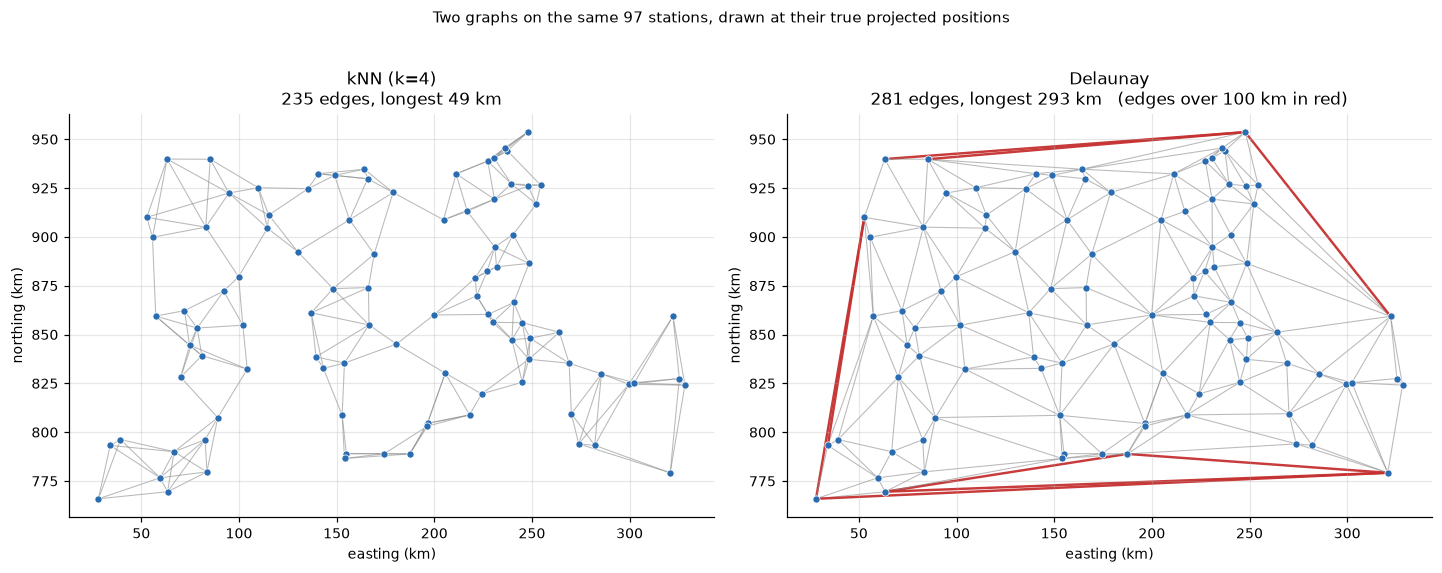

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
xy = {i: (Ppos[i, 0] / 1000, Ppos[i, 1] / 1000) for i in range(n)}   # km, for readable ticks

for ax, (name, g) in zip(axes, GRAPHS.items()):
    el = np.array([Dphys[a, b] for a, b in g.edges()]) / 1000.0
    for (a, b), length in zip(g.edges(), el):
        ax.plot([xy[a][0], xy[b][0]], [xy[a][1], xy[b][1]],
                color=C_RED if length > 100 else "0.55",
                lw=1.6 if length > 100 else 0.7,
                alpha=0.95 if length > 100 else 0.6, zorder=1)
    ax.scatter(Ppos[:, 0] / 1000, Ppos[:, 1] / 1000, s=22, c=C_LINE,
               edgecolor="white", linewidth=0.5, zorder=3)
    ax.set_aspect("equal")            # equal axis scaling: a km is a km on both axes
    ax.set_xlabel("easting (km)")
    ax.set_ylabel("northing (km)")
    ax.set_title(f"{name}\n{g.number_of_edges()} edges, longest {el.max():.0f} km"
                 + ("   (edges over 100 km in red)" if (el > 100).any() else ""))
fig.suptitle(f"Two graphs on the same {n} stations, drawn at their true projected positions",
             fontsize=10)
plt.show()

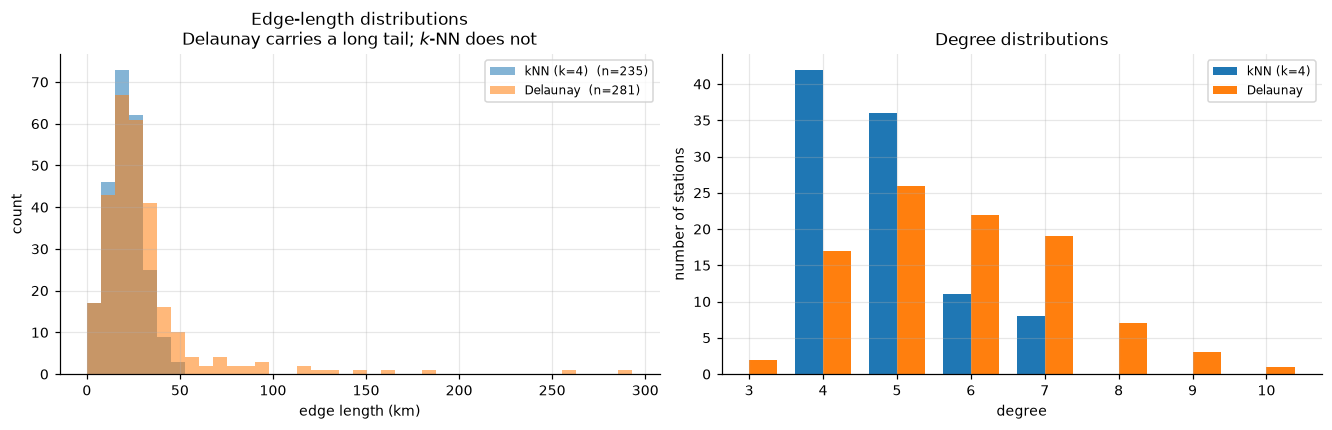

kNN (k=4)        edges over 100 km:   0   over 150 km:   0
Delaunay         edges over 100 km:   9   over 150 km:   4


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, max(e.max() for e in edge_lengths.values()), 40)
for name, el in edge_lengths.items():
    axes[0].hist(el, bins=bins, alpha=0.55, label=f"{name}  (n={len(el)})")
axes[0].set_xlabel("edge length (km)")
axes[0].set_ylabel("count")
axes[0].set_title("Edge-length distributions\nDelaunay carries a long tail; $k$-NN does not")
axes[0].legend(fontsize=8)

width = 0.38
for offset, (name, g) in zip((-width / 2, width / 2), GRAPHS.items()):
    degs = np.array([dg for _, dg in g.degree()])
    vals, counts = np.unique(degs, return_counts=True)
    axes[1].bar(vals + offset, counts, width=width, label=name)
axes[1].set_xlabel("degree")
axes[1].set_ylabel("number of stations")
axes[1].set_title("Degree distributions")
axes[1].legend(fontsize=8)
plt.show()

for name, el in edge_lengths.items():
    print(f"{name:16s} edges over 100 km: {int((el > 100).sum()):3d}   "
          f"over 150 km: {int((el > 150).sum()):3d}")

The maps show the difference plainly. The $k$-NN graph is a local mesh: every edge is short, and the
offshore stations on Cape Cod, Martha's Vineyard, and Nantucket connect only to their nearest
mainland or island neighbours. The Delaunay graph triangulates the **entire convex hull**, which
forces long edges along the boundary — the longest spans nearly 300 km, joining stations that share
no meteorology whatsoever.

Those long red edges are a genuine modelling artefact, not a quirk of plotting. Because every edge
has weight 1, the Laplacian charges the same Dirichlet energy for disagreement across a 293 km edge
as across a 5 km one. Delaunay's boundary edges therefore inject an assumption — *these far-apart
stations should have similar temperatures* — that nobody would defend if stated out loud. Section 4
measures what it costs.

> 📖 **Reference — neighbourhood graph construction.**
> [von Luxburg, *A Tutorial on Spectral Clustering* (2007)](https://arxiv.org/abs/0711.0189),
> Section 2.2 ("Different similarity graphs") and Section 8. It sets out the $\varepsilon$-ball,
> $k$-NN, mutual-$k$-NN and fully connected constructions and discusses how each behaves under
> uneven sampling density — directly relevant here, since our stations are far denser around Boston
> and Hartford than in western Massachusetts.
>
> 📖 **Reference — the triangulation.**
> [`scipy.spatial.Delaunay`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html).
> Note `simplices` returns triangles as index triples, which we expand into the three undirected
> edges; and that the triangulation is of the **convex hull**, which is precisely where the long
> boundary edges come from.


---
## 3. Reading the spectral modes geographically

For each graph we build the combinatorial Laplacian and diagonalise it:

$$L = D - A = U\Lambda U^\top, \qquad L u_k = \lambda_k u_k, \qquad 0=\lambda_1 \le \cdots \le \lambda_n,$$

where $A$ is the binary adjacency matrix in the canonical station order, $D$ holds the degrees, $U$
has the orthonormal eigenvectors as columns, and $\Lambda = \operatorname{diag}(\lambda_k)$. This is
the same object as in Lessons 1 and 2 — only the edge set is new.


kNN (k=4)        lambda_2 =   0.0253   lambda_max =  8.7083   zero eigenvalues = 1
Delaunay         lambda_2 =   0.2926   lambda_max = 11.5437   zero eigenvalues = 1


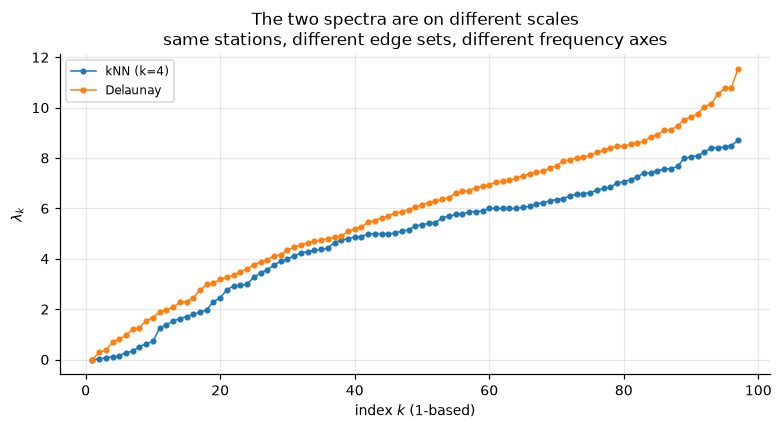

In [11]:
OPS = {}
for name, g in GRAPHS.items():
    A = nx.to_numpy_array(g, nodelist=range(n), weight=None)
    L = np.diag(A.sum(axis=1)) - A
    lam, U = np.linalg.eigh(L)
    idx = np.argsort(lam)
    OPS[name] = {"g": g, "A": A, "L": L, "lam": lam[idx], "U": U[:, idx],
                 "m": g.number_of_edges()}
    print(f"{name:16s} lambda_2 = {lam[idx][1]:8.4f}   lambda_max = {lam[idx][-1]:7.4f}   "
          f"zero eigenvalues = {int(np.sum(np.abs(lam) < 1e-8))}")

fig, ax = plt.subplots(figsize=(7.0, 3.8))
for name, op in OPS.items():
    ax.plot(np.arange(1, n + 1), op["lam"], "o-", ms=3, lw=1, label=name)
ax.set_xlabel("index $k$ (1-based)")
ax.set_ylabel(r"$\lambda_k$")
ax.set_title("The two spectra are on different scales\n"
             "same stations, different edge sets, different frequency axes")
ax.legend(fontsize=8)
plt.show()

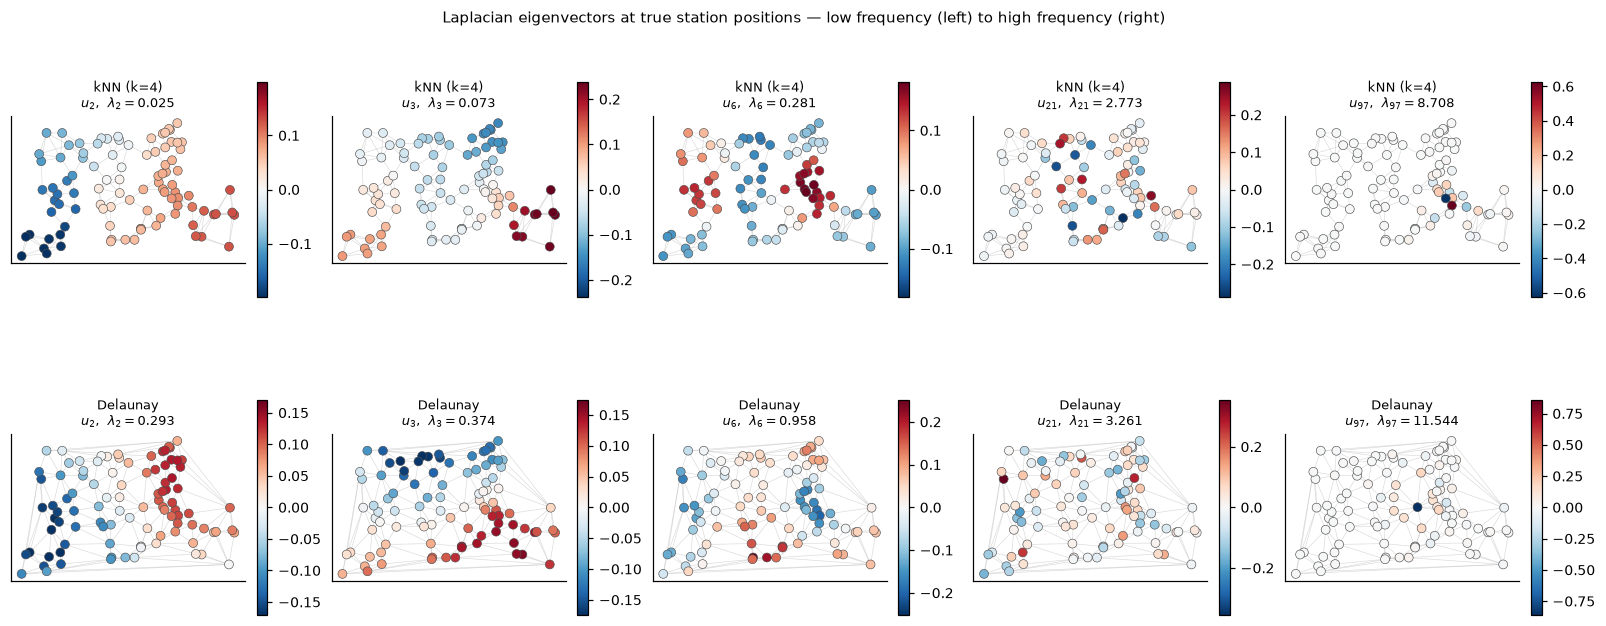

In [12]:
def map_signal(ax, values, title, cmap="RdBu_r", centre=None, show_edges=None, cbar_label=None):
    # Draw a per-station quantity at true projected positions.
    if centre is None:
        vmin, vmax = float(np.min(values)), float(np.max(values))
    else:
        mm = float(np.abs(values - centre).max())
        vmin, vmax = centre - mm, centre + mm
    if show_edges is not None:
        for a, b in show_edges.edges():
            ax.plot([xy[a][0], xy[b][0]], [xy[a][1], xy[b][1]],
                    color="0.75", lw=0.4, alpha=0.6, zorder=1)
    sc = ax.scatter(Ppos[:, 0] / 1000, Ppos[:, 1] / 1000, c=values, cmap=cmap,
                    vmin=vmin, vmax=vmax, s=34, edgecolor="0.3", linewidth=0.4, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=8.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return sc

SHOW_MODES = [1, 2, 5, 20, 96]           # NumPy indices: u_2, u_3, u_6, u_21, u_97
fig, axes = plt.subplots(2, len(SHOW_MODES), figsize=(14.5, 6.0))
for row, (name, op) in enumerate(OPS.items()):
    for col, k in enumerate(SHOW_MODES):
        sc = map_signal(axes[row, col], op["U"][:, k],
                        f"{name}\n$u_{{{k + 1}}}$,  $\\lambda_{{{k + 1}}}={op['lam'][k]:.3f}$",
                        centre=0.0, show_edges=op["g"])
        fig.colorbar(sc, ax=axes[row, col], fraction=0.046)
fig.suptitle("Laplacian eigenvectors at true station positions — "
             "low frequency (left) to high frequency (right)", fontsize=10)
plt.show()

The low modes are geographically coherent: $u_2$ separates the region into two broad areas, $u_3$
into a different pair. That is not a coincidence — it is the bottleneck logic of Lesson 1, applied to
a graph whose bottlenecks happen to be geographic, because the edges were built from geography.

The differences between the two rows are subtler than they first look, and worth measuring rather
than eyeballing. Both graphs put a **west–east** division at $u_2$ (correlation with easting $+0.93$
and $+0.86$) and a **north–south** one at $u_3$. On the *orientation* of the leading modes they
agree.

Where they disagree is what that division **costs**. Splitting the $k$-NN graph along the sign of
$u_2$ severs only **4 edges**; splitting Delaunay along its own $u_2$ severs **24**. Delaunay's long
convex-hull edges stitch the two halves together, so the same geographic cut is far more expensive
there — which is exactly why $\lambda_2$ is $0.025$ on one graph and $0.293$ on the other, a factor
of twelve. The graphs agree about *where* the region divides and disagree about *how strongly*.

High modes are localised: single stations flipping against their neighbours, with no geographic
story at all.

### Three different notions of distance

Spatial graph analysis has three, and conflating them causes most of the confusion in this area.

| Quantity | Units | Depends on |
|---|---|---|
| **Physical distance** $d^{\mathrm{phys}}_{ij} = \lVert p_i-p_j\rVert$ | metres | coordinates only |
| **Graph distance** (shortest path, in hops) | hops — dimensionless | edge set only |
| **Graph frequency** $\lambda_k$ | dimensionless | edge set only |

Only the first knows about kilometres. The other two are consequences of $E$, and $E$ was built from
coordinates — but once built, it has forgotten them.


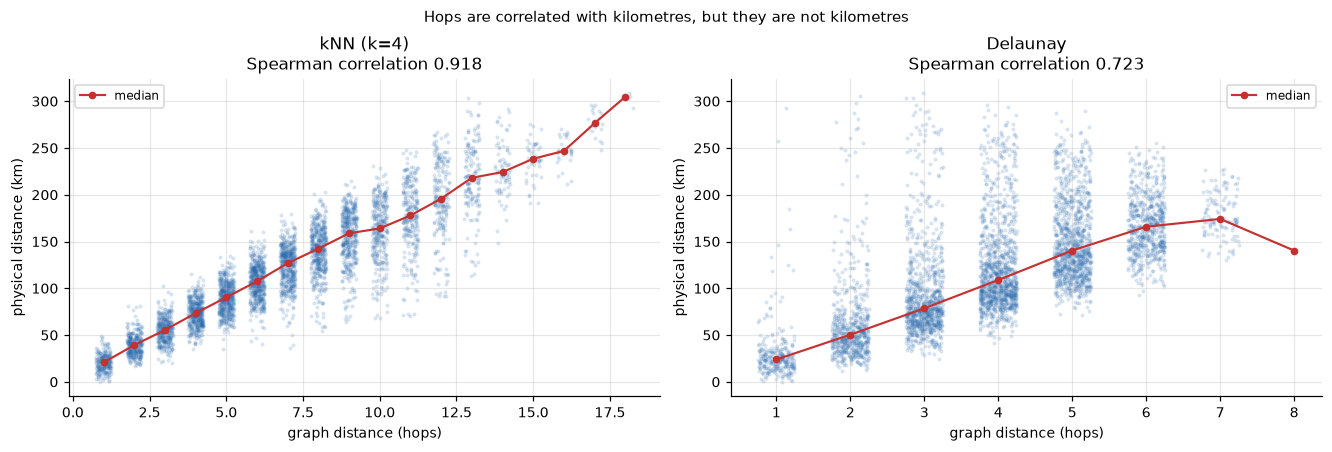

In [13]:
# How well does hop distance track physical distance? (It is a construction-dependent question.)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
for ax, (name, op) in zip(axes, OPS.items()):
    hops = dict(nx.all_pairs_shortest_path_length(op["g"]))
    iu = np.triu_indices(n, 1)
    h = np.array([hops[a][b] for a, b in zip(*iu)])
    p_km = Dphys[iu] / 1000.0
    ax.scatter(h + rng.uniform(-0.25, 0.25, size=h.size), p_km, s=3, alpha=0.12, color=C_LINE)
    med = [np.median(p_km[h == v]) for v in range(1, h.max() + 1)]
    ax.plot(range(1, h.max() + 1), med, "o-", color=C_RED, ms=4, lw=1.4, label="median")
    ax.set_xlabel("graph distance (hops)")
    ax.set_ylabel("physical distance (km)")
    ax.set_title(f"{name}\nSpearman correlation {pd.Series(h).corr(pd.Series(p_km), method='spearman'):.3f}")
    ax.legend(fontsize=8)
fig.suptitle("Hops are correlated with kilometres, but they are not kilometres", fontsize=10)
plt.show()

The relationship is strong but far from deterministic, and it is much looser for Delaunay: one hop
there can mean 5 km or 293 km. A "two-hop neighbourhood" is therefore not a fixed physical radius,
and any sentence of the form "this mode has a wavelength of about 40 km" is at best an average over
a wide spread.

### Why $\lambda_k$ is not measured in cycles per kilometre

On a regular grid with spacing $h$, Laplacian eigenvectors are sinusoids and $\lambda$ maps cleanly
to a spatial frequency in cycles per unit length. None of that survives here:

1. **Our graph is unweighted.** $L$ sees a 5 km edge and a 100 km edge as identical, so nothing in
   the operator carries a length scale at all. $\lambda_k$ is dimensionless.
2. **Station density is wildly uneven** — dense around Boston, sparse in western Massachusetts — so
   even a fixed number of hops covers different distances in different places.
3. **$\lambda_{\max}$ depends on degree, not geometry.** It is bounded below by $d_{\max}+1$, so
   adding a well-connected station raises the top of the frequency axis without anything physical
   changing.

The defensible statement is the one from Lesson 1: $\lambda_k = u_k^\top L u_k$ is the Dirichlet
energy of $u_k$ — how much that pattern disagrees **across edges**. Recovering genuine cycles per
kilometre would require distance-dependent edge weights, which is the next lesson.

### Coordinates enter only through $E$ — demonstrated

Here is the claim that most distinguishes a graph transform from a spatial one: **once $L$ is fixed,
moving the stations on the map changes nothing.** We rotate, translate, and rescale every position,
keeping the edge set as it is, and recompute the transform.


In [14]:
theta = np.deg2rad(37.0)
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
Ppos_moved = (Ppos @ R.T) * 2.5 + np.array([1.0e6, -4.0e5])     # rotate, scale, translate

op = OPS[f"kNN (k={K_NN})"]
z = x - x.mean()
# Snapshot under a distinct name: later cells unpack a loop variable called `zhat`,
# and reusing that name here would leave this reference pointing at another graph.
zhat_knn_ref = op["U"].T @ z

print("After rotating by 37 degrees, scaling by 2.5 and translating:")
print(f"  positions actually moved      : {np.abs(Ppos_moved - Ppos).max() / 1000:.0f} km max")
print(f"  edge set unchanged (by fiat)  : True")
print(f"  Laplacian unchanged           : identical object, not recomputed")
print(f"  GFT coefficients unchanged    : {np.allclose(op['U'].T @ z, zhat_knn_ref)}")
print()
print("But rebuilding the GRAPH from the moved coordinates is a different matter.")
print("A rotation+scale+translation is a similarity transform, so it preserves the")
print("ORDER of distances -- and therefore both constructions are unchanged too:")
Dmoved = np.hypot(Ppos_moved[:, 0][:, None] - Ppos_moved[:, 0][None, :],
                  Ppos_moved[:, 1][:, None] - Ppos_moved[:, 1][None, :])
knn_moved = nx.Graph(); knn_moved.add_nodes_from(range(n))
for i, nb in enumerate(np.argsort(Dmoved, axis=1)[:, 1:K_NN + 1]):
    for j in nb: knn_moved.add_edge(i, int(j))
print(f"  same kNN edge set after moving: "
      f"{set(map(frozenset, knn_moved.edges())) == set(map(frozenset, op['g'].edges()))}")
print()
print("Now a NON-similarity transform -- stretch easting by 3x, leave northing alone:")
Pstretch = Ppos * np.array([3.0, 1.0])
Dstretch = np.hypot(Pstretch[:, 0][:, None] - Pstretch[:, 0][None, :],
                    Pstretch[:, 1][:, None] - Pstretch[:, 1][None, :])
knn_stretch = nx.Graph(); knn_stretch.add_nodes_from(range(n))
for i, nb in enumerate(np.argsort(Dstretch, axis=1)[:, 1:K_NN + 1]):
    for j in nb: knn_stretch.add_edge(i, int(j))
same = set(map(frozenset, knn_stretch.edges())) == set(map(frozenset, op["g"].edges()))
A_s = nx.to_numpy_array(knn_stretch, nodelist=range(n), weight=None)
lam_s = np.linalg.eigvalsh(np.diag(A_s.sum(axis=1)) - A_s)
print(f"  same edge set : {same}")
print(f"  edges differing: "
      f"{len(set(map(frozenset, knn_stretch.edges())) ^ set(map(frozenset, op['g'].edges())))}")
print(f"  lambda_2      : {lam_s[1]:.4f}  vs  {op['lam'][1]:.4f} before")

After rotating by 37 degrees, scaling by 2.5 and translating:
  positions actually moved      : 941 km max
  edge set unchanged (by fiat)  : True
  Laplacian unchanged           : identical object, not recomputed
  GFT coefficients unchanged    : True

But rebuilding the GRAPH from the moved coordinates is a different matter.
A rotation+scale+translation is a similarity transform, so it preserves the
ORDER of distances -- and therefore both constructions are unchanged too:
  same kNN edge set after moving: True

Now a NON-similarity transform -- stretch easting by 3x, leave northing alone:
  same edge set : False
  edges differing: 160
  lambda_2      : 0.0111  vs  0.0253 before


Two conclusions, and they are easy to run together by mistake:

- **Holding $L$ fixed, coordinates are irrelevant.** The GFT is a property of the edge set. Redrawing
  the map — the spring layouts of Lessons 1 and 2, or the projected positions here — changes the
  picture and not one coefficient.
- **Changing coordinates and *rebuilding* the graph is a different operation.** A similarity
  transform preserves distance ordering, so both constructions survive it unchanged. An anisotropic
  stretch does not: it rewires the graph and moves the spectrum.

The practical reading is that the choice of projection matters exactly insofar as it changes which
pairs are nearest — which is why we measured its distortion in Section 2 rather than assuming it
away.

> 📖 **Reference — spectral analysis on irregular domains.**
> [Shuman et al., *The Emerging Field of Signal Processing on Graphs*
> (2013)](https://arxiv.org/abs/1211.0053), Sections II–III. The framing of $\lambda_k$ as a
> frequency, the zero-crossing intuition, and the discussion of irregular domains all apply directly.
> Note what the paper does *not* claim: that graph frequency has physical units. Section V-A
> discusses distance-based edge weighting, the step we are deferring.


---
## 4. The same temperature on two different graphs

Now the signal. With the canonical station order fixed, let $x \in \mathbb{R}^{97}$ hold the
temperatures in °C and let

$$\bar{x} = \frac1n\sum_i x_i, \qquad z = x - \bar{x}\mathbf{1}$$

be the mean-centred field. We transform $z$ rather than $x$ because, as Lesson 2 showed, the constant
mode carries only the regional average — here about $27\,^\circ$C — and would dominate every energy
plot while saying nothing about spatial structure.


mean temperature  xbar = 27.228 degC
centred signal z: min -3.93, max +4.97, ||z||^2 = 282.71 degC^2


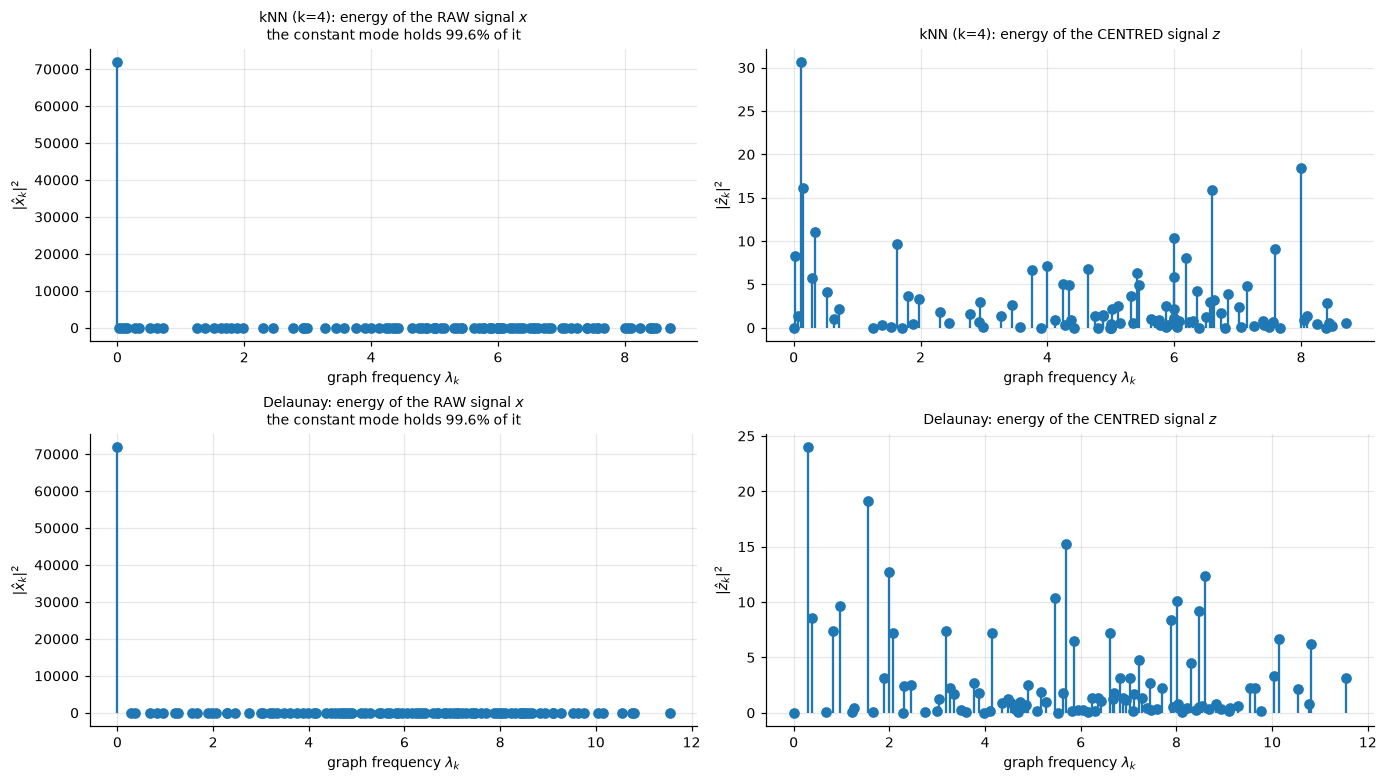

In [15]:
x_bar = x.mean()
z = x - x_bar
print(f"mean temperature  xbar = {x_bar:.3f} degC")
print(f"centred signal z: min {z.min():+.2f}, max {z.max():+.2f}, "
      f"||z||^2 = {z @ z:.2f} degC^2")

for name, op in OPS.items():
    op["zhat"] = op["U"].T @ z
    op["xhat"] = op["U"].T @ x

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0))
for row, (name, op) in enumerate(OPS.items()):
    axes[row, 0].stem(op["lam"], op["xhat"] ** 2, basefmt=" ")
    axes[row, 0].set_title(f"{name}: energy of the RAW signal $x$\n"
                           f"the constant mode holds "
                           f"{100 * op['xhat'][0] ** 2 / (x @ x):.1f}% of it", fontsize=9)
    axes[row, 0].set_ylabel(r"$|\hat{x}_k|^2$")
    axes[row, 1].stem(op["lam"], op["zhat"] ** 2, basefmt=" ")
    axes[row, 1].set_title(f"{name}: energy of the CENTRED signal $z$", fontsize=9)
    axes[row, 1].set_ylabel(r"$|\hat{z}_k|^2$")
    for c in (0, 1):
        axes[row, c].set_xlabel(r"graph frequency $\lambda_k$")
plt.show()

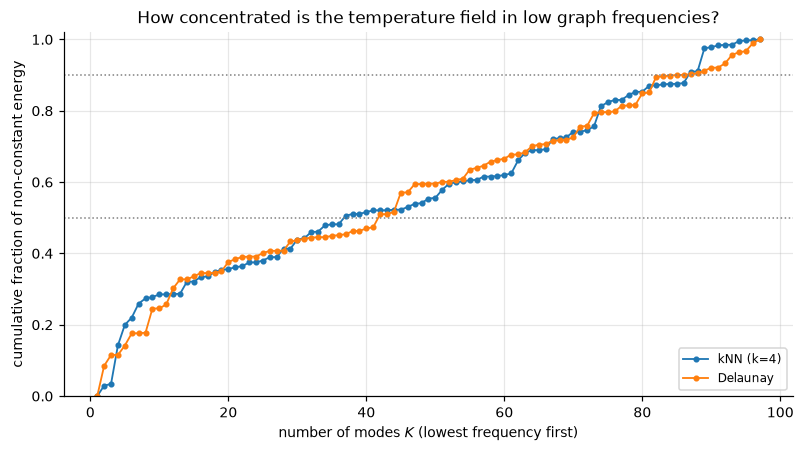

graph             K for 50%  K for 90%   energy in k=2..5
kNN (k=4)                37         87              20.0%
Delaunay                 42         85              14.2%

For comparison, Lesson 2's club-membership signal put 66% of its non-constant
energy in a SINGLE mode. Nothing like that is happening here.


In [16]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
for name, op in OPS.items():
    e = op["zhat"] ** 2
    ax.plot(np.arange(1, n + 1), np.cumsum(e) / e.sum(), "o-", ms=3, lw=1.2, label=name)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.axhline(0.9, color="gray", ls=":", lw=1)
ax.set_xlabel("number of modes $K$ (lowest frequency first)")
ax.set_ylabel("cumulative fraction of non-constant energy")
ax.set_title("How concentrated is the temperature field in low graph frequencies?")
ax.legend(fontsize=8)
ax.set_ylim(0, 1.02)
plt.show()

print(f"{'graph':16s}{'K for 50%':>11s}{'K for 90%':>11s}{'energy in k=2..5':>19s}")
for name, op in OPS.items():
    e = op["zhat"] ** 2
    cum = np.cumsum(e) / e.sum()
    print(f"{name:16s}{int(np.searchsorted(cum, 0.5) + 1):11d}{int(np.searchsorted(cum, 0.9) + 1):11d}"
          f"{100 * e[1:5].sum() / e.sum():18.1f}%")
print()
print("For comparison, Lesson 2's club-membership signal put 66% of its non-constant")
print("energy in a SINGLE mode. Nothing like that is happening here.")

That is the first substantive finding, and it is a deflating one: the temperature field is **not**
strongly concentrated at low graph frequency. It takes tens of modes to capture half the energy.
Before drawing conclusions, we quantify the smoothness properly.

### Dirichlet energy, and why raw values cannot be compared across graphs

From Lesson 1 (edge form) and Lesson 2 (spectral form):

$$z^\top L z \;=\; \sum_{\{i,j\}\in E} (z_i-z_j)^2 \;=\; \sum_{k=1}^{n} \lambda_k\,|\widehat{z}_k|^2 .$$

Both sides have units of $(^\circ\mathrm{C})^2$. But the middle expression sums over **edges**, and
our two graphs have different numbers of them — 235 against 281. A graph with more edges will show a
larger Dirichlet energy for the *same* signal purely by having more terms to add, with no change in
smoothness whatsoever.

So we also report the **mean squared difference per edge**,

$$\frac{z^\top L z}{|E|} \;=\; \frac{1}{|E|}\sum_{\{i,j\}\in E}(z_i-z_j)^2 ,$$

whose square root is an interpretable "typical temperature difference between connected stations",
in °C.


In [17]:
print(f"{'graph':16s}{'|E|':>6s}{'z^T L z':>11s}{'spectral':>11s}{'per edge':>11s}"
      f"{'RMS diff (degC)':>17s}")
for name, op in OPS.items():
    L, lam, zhat, m = op["L"], op["lam"], op["zhat"], op["m"]
    edge_form = sum((z[a] - z[b]) ** 2 for a, b in op["g"].edges())
    spectral = float((lam * zhat ** 2).sum())
    de = float(z @ L @ z)
    assert np.isclose(de, edge_form) and np.isclose(de, spectral)
    op["dirichlet"] = de
    print(f"{name:16s}{m:6d}{de:11.2f}{spectral:11.2f}{de / m:11.4f}{np.sqrt(de / m):17.3f}")
print()
print("All three forms agree exactly, as they must. Note the raw energies differ by 24%")
print("while the per-edge figures differ by under 4% -- almost all of the raw gap is just")
print("Delaunay having more edges, not the signal being rougher on it.")

graph              |E|    z^T L z   spectral   per edge  RMS diff (degC)
kNN (k=4)          235    1136.80    1136.80     4.8374            2.199
Delaunay           281    1409.72    1409.72     5.0168            2.240

All three forms agree exactly, as they must. Note the raw energies differ by 24%
while the per-edge figures differ by under 4% -- almost all of the raw gap is just
Delaunay having more edges, not the signal being rougher on it.


### Is the field smoother than chance?

Same null model as Lesson 2, and the same logic: hold the graph fixed and **permute the temperatures
across stations**. That destroys any relationship between value and location while keeping the
multiset of temperatures and the graph exactly as they are. If the observed Dirichlet energy is not
unusually low against that ensemble, then the graph is telling us nothing about the field.


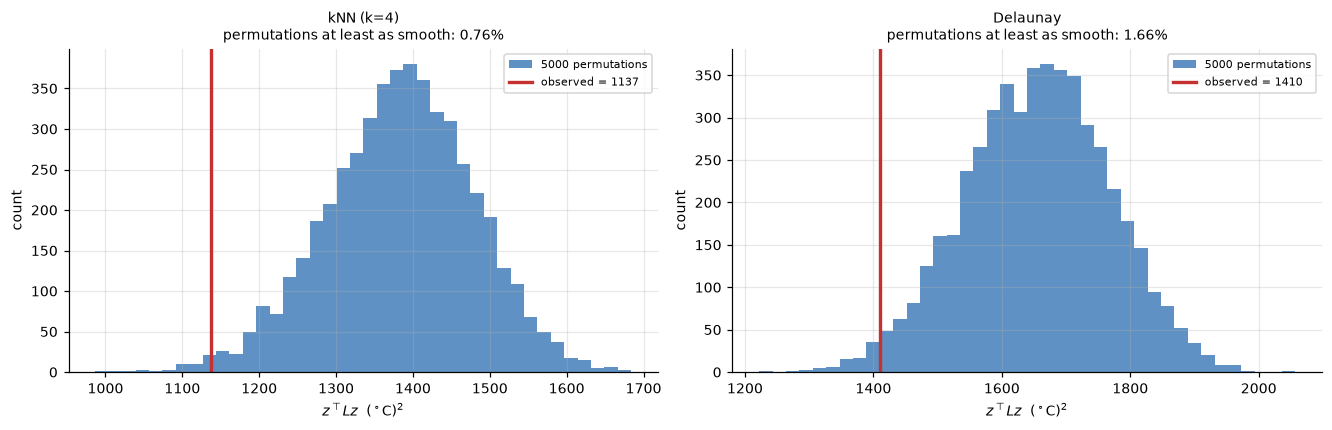

kNN (k=4)        observed   1136.8   null mean   1383.4   ratio 0.822   p = 0.0076
Delaunay         observed   1409.7   null mean   1654.8   ratio 0.852   p = 0.0166


In [18]:
N_NULL = 5000
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, op) in zip(axes, OPS.items()):
    L = op["L"]
    null = np.empty(N_NULL)
    for s in range(N_NULL):
        zp = rng.permutation(z)
        null[s] = zp @ L @ zp
    op["null"] = null
    pct = float(np.mean(null <= op["dirichlet"]))
    op["null_pct"] = pct
    ax.hist(null, bins=40, color=C_LINE, alpha=0.75, label=f"{N_NULL} permutations")
    ax.axvline(op["dirichlet"], color=C_RED, lw=2.2,
               label=f"observed = {op['dirichlet']:.0f}")
    ax.set_xlabel(r"$z^\top L z$  $(^\circ$C$)^2$")
    ax.set_ylabel("count")
    ax.set_title(f"{name}\npermutations at least as smooth: {pct:.2%}", fontsize=9)
    ax.legend(fontsize=7.5)
plt.show()

for name, op in OPS.items():
    print(f"{name:16s} observed {op['dirichlet']:8.1f}   null mean {op['null'].mean():8.1f}   "
          f"ratio {op['dirichlet'] / op['null'].mean():.3f}   p = {op['null_pct']:.4f}")

The field **is** smoother than chance on both graphs — the 1st percentile on $k$-NN, the 2nd on
Delaunay — so geography is
carrying real information. But the effect is modest: the observed energy is about 82–85% of the
permutation mean, not the order-of-magnitude separation Lesson 2 found for club membership (below
the minimum of 5000 shuffles) or for grid voltage angle. On a summer day in New England, neighbouring
stations differ by roughly $2.2\,^\circ$C on average, and shuffling the labels only raises that to
about $2.4\,^\circ$C.

> ⚠️ **Coefficient $k$ does not mean the same thing on the two graphs.** Each graph supplies its own
> orthonormal basis. There is no reason $u_k$ of the $k$-NN graph should resemble $u_k$ of the
> Delaunay graph. In practice the lowest few modes here do line up reasonably well — they report the
> same broad geography — but the correspondence decays quickly with $k$ and is gone by $k=50$, so a
> coefficient comparison that is defensible at $k=2$ is meaningless at $k=50$. Only quantities defined
> without reference to a particular basis — total energy, Dirichlet energy per edge, reconstruction
> error at a given $K$ — can be compared across constructions at every $k$. The cell below measures
> where the correspondence breaks down.


In [19]:
Ua = OPS[f"kNN (k={K_NN})"]["U"]
Ub = OPS["Delaunay"]["U"]
overlap = np.abs(Ua.T @ Ub)            # |<u_j^kNN, u_k^Delaunay>|

print("How well does mode k of one graph line up with mode k of the other?")
print(f"{'k':>4s}{'|<u_k^kNN, u_k^Del>|':>22s}{'best-matching Delaunay mode':>30s}")
for k in [1, 2, 3, 4, 9, 19, 49]:
    j = int(np.argmax(overlap[k]))
    print(f"{k + 1:4d}{overlap[k, k]:22.3f}{f'u_{j + 1} (overlap {overlap[k, j]:.3f})':>30s}")
print()
sub = 10
print(f"Subspace agreement instead of mode-by-mode: the {sub} lowest non-constant modes")
print(f"of the two graphs span subspaces whose principal angles give an average")
print(f"alignment of {np.linalg.norm(Ua[:, 1:sub+1].T @ Ub[:, 1:sub+1], 'fro') ** 2 / sub:.3f} "
      f"(1.0 would be identical subspaces).")
print()
print("-> The LOWEST modes correspond quite well (0.6-0.8 overlap): both graphs find the")
print("   same broad geography. Correspondence collapses for higher modes, where each")
print("   graph's local wiring takes over. So low-frequency coefficients are roughly")
print("   comparable between constructions; high-frequency ones are not comparable at all.")

How well does mode k of one graph line up with mode k of the other?
   k  |<u_k^kNN, u_k^Del>|   best-matching Delaunay mode
   2                 0.811           u_2 (overlap 0.811)
   3                 0.682           u_3 (overlap 0.682)
   4                 0.740           u_4 (overlap 0.740)
   5                 0.614           u_5 (overlap 0.614)
  10                 0.229           u_8 (overlap 0.527)
  20                 0.380          u_20 (overlap 0.380)
  50                 0.077          u_57 (overlap 0.396)

Subspace agreement instead of mode-by-mode: the 10 lowest non-constant modes
of the two graphs span subspaces whose principal angles give an average
alignment of 0.754 (1.0 would be identical subspaces).

-> The LOWEST modes correspond quite well (0.6-0.8 overlap): both graphs find the
   same broad geography. Correspondence collapses for higher modes, where each
   graph's local wiring takes over. So low-frequency coefficients are roughly
   comparable between construct

---
## 5. Reconstruction, filtering, and whether this is useful

### Truncated reconstruction

Keeping the mean and the $K-1$ lowest non-constant modes:

$$x^{(K)} \;=\; \bar{x}\,\mathbf{1} \;+\; \sum_{k=2}^{K} \widehat{z}_k\, u_k .$$

The $k=1$ term is dropped from the sum because $u_1$ is the constant mode and $\widehat{z}_1 = 0$ by
construction — the mean is restored explicitly by the $\bar{x}\mathbf{1}$ term instead. We report
error as RMSE in °C, which is directly interpretable, rather than as a relative norm.


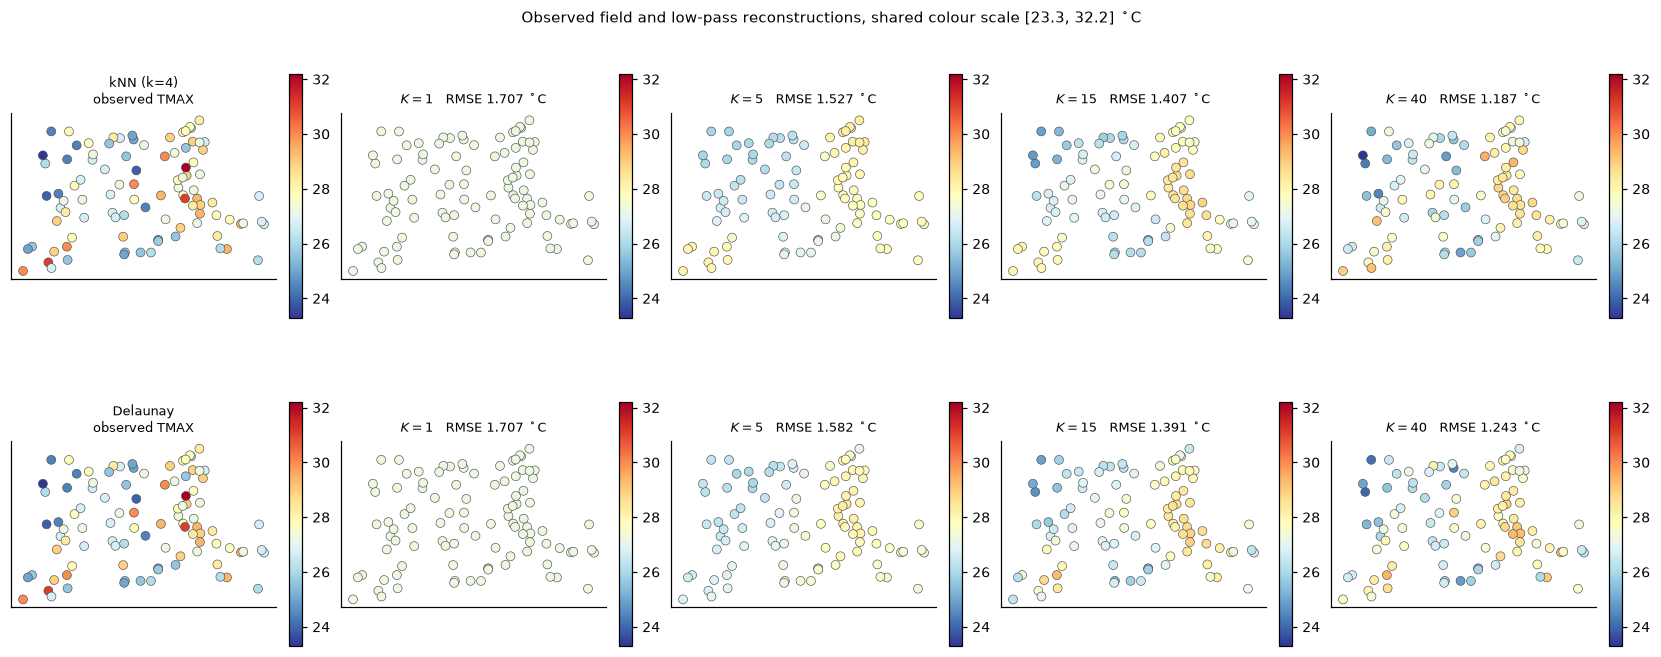

In [20]:
def reconstruct(op, K):
    # xbar * 1  +  sum_{k=2}^{K} zhat_k u_k
    kept = np.zeros(n)
    kept[1:K] = op["zhat"][1:K]
    return x_bar + op["U"] @ kept

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

for name, op in OPS.items():
    op["rmse_curve"] = np.array([rmse(x, reconstruct(op, K)) for K in range(1, n + 1)])

SHOW_K = [1, 5, 15, 40]
fig, axes = plt.subplots(len(OPS), len(SHOW_K) + 1, figsize=(15, 6.2))
vmin, vmax = float(x.min()), float(x.max())
for row, (name, op) in enumerate(OPS.items()):
    sc = map_signal(axes[row, 0], x, f"{name}\nobserved TMAX", cmap="RdYlBu_r")
    fig.colorbar(sc, ax=axes[row, 0], fraction=0.046)
    for col, K in enumerate(SHOW_K, start=1):
        rec = reconstruct(op, K)
        sc = map_signal(axes[row, col], rec,
                        f"$K={K}$   RMSE {rmse(x, rec):.3f} $^\\circ$C", cmap="RdYlBu_r")
        sc.set_clim(vmin, vmax)
        fig.colorbar(sc, ax=axes[row, col], fraction=0.046)
fig.suptitle("Observed field and low-pass reconstructions, shared colour scale "
             f"[{vmin:.1f}, {vmax:.1f}] $^\\circ$C", fontsize=10)
plt.show()

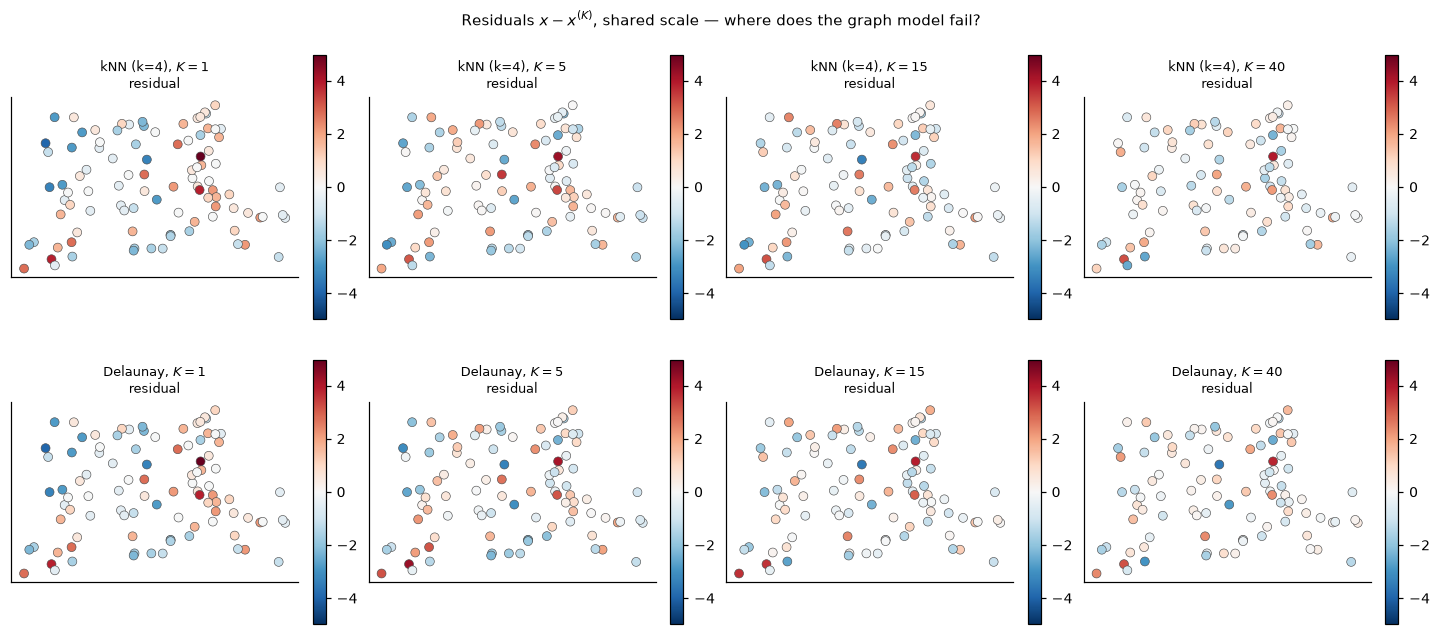

In [21]:
fig, axes = plt.subplots(len(OPS), len(SHOW_K), figsize=(13, 5.8))
resid_max = max(np.abs(x - reconstruct(op, K)).max() for op in OPS.values() for K in SHOW_K)
for row, (name, op) in enumerate(OPS.items()):
    for col, K in enumerate(SHOW_K):
        r = x - reconstruct(op, K)
        sc = map_signal(axes[row, col], r, f"{name}, $K={K}$\nresidual", centre=0.0)
        sc.set_clim(-resid_max, resid_max)
        fig.colorbar(sc, ax=axes[row, col], fraction=0.046)
fig.suptitle("Residuals $x - x^{(K)}$, shared scale — where does the graph model fail?",
             fontsize=10)
plt.show()

### Does this beat simply not using a graph?

An RMSE curve alone cannot answer "is this useful?" — it needs something to beat. Three baselines,
each requiring no graph at all:

- **Mean only** — predict $\bar{x}$ everywhere. One parameter. This is exactly $K=1$.
- **Elevation, linear** — regress temperature on station elevation. Two parameters. Physically
  motivated: air cools with height, and our stations span 486 m.
- **Planar trend** — regress on easting and northing. Three parameters. Captures a regional gradient.

These matter because the graph construction used coordinates but **never used elevation**, and
elevation is a real driver of temperature. If a two-parameter regression on a variable the graph
ignores beats a dozen graph modes, that is worth knowing before anyone builds a pipeline on this.


In [22]:
def ols_rmse(design):
    beta, *_ = np.linalg.lstsq(design, x, rcond=None)
    return rmse(x, design @ beta), design.shape[1]

ones = np.ones(n)
BASELINES = {
    "mean only": ols_rmse(np.column_stack([ones])),
    "elevation (linear)": ols_rmse(np.column_stack([ones, elev])),
    "planar trend (e, n)": ols_rmse(np.column_stack([ones, Ppos[:, 0], Ppos[:, 1]])),
    "elevation + planar trend": ols_rmse(np.column_stack([ones, elev, Ppos[:, 0], Ppos[:, 1]])),
}
print(f"correlation of TMAX with elevation: {np.corrcoef(x, elev)[0, 1]:+.3f}")
print()
print(f"{'baseline (no graph)':30s}{'params':>8s}{'RMSE degC':>12s}")
for name, (r, p) in BASELINES.items():
    print(f"{name:30s}{p:8d}{r:12.4f}")
print()
print(f"{'graph':16s}{'modes needed to match each baseline':>40s}")
for name, op in OPS.items():
    line = f"{name:16s}"
    for bname, (r, p) in BASELINES.items():
        k = next((K for K in range(1, n + 1) if op["rmse_curve"][K - 1] <= r), None)
        line += f"  {bname.split(' (')[0][:12]}: K={k if k else '>n'}"
    print(line)

correlation of TMAX with elevation: -0.447

baseline (no graph)             params   RMSE degC
mean only                            1      1.7072
elevation (linear)                   2      1.5269
planar trend (e, n)                  3      1.6417
elevation + planar trend             4      1.5191

graph                modes needed to match each baseline
kNN (k=4)         mean only: K=1  elevation: K=6  planar trend: K=4  elevation + : K=6
Delaunay          mean only: K=1  elevation: K=9  planar trend: K=2  elevation + : K=9


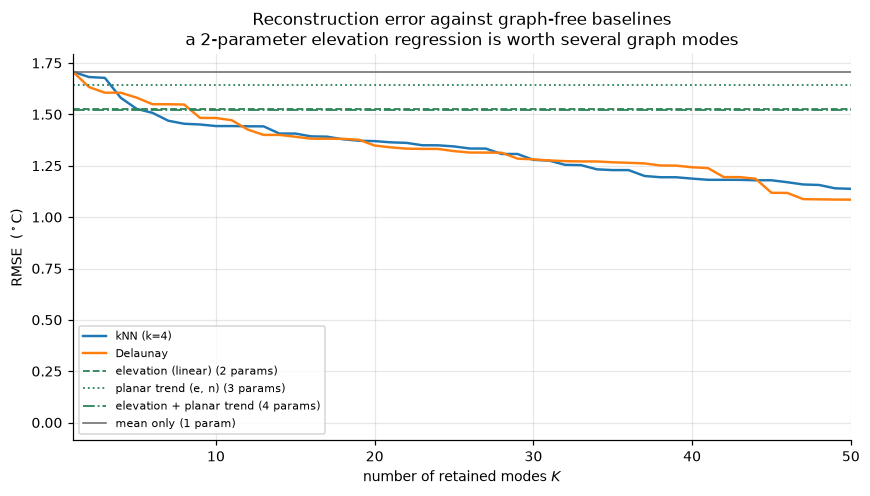

In [23]:
fig, ax = plt.subplots(figsize=(7.8, 4.4))
for name, op in OPS.items():
    ax.plot(np.arange(1, n + 1), op["rmse_curve"], "-", lw=1.6, label=name)
for (bname, (r, p)), style in zip(BASELINES.items(), ["-", "--", ":", "-."]):
    if bname == "mean only":
        continue
    ax.axhline(r, color=C_GREEN, ls=style, lw=1.2, label=f"{bname} ({p} params)")
ax.axhline(BASELINES["mean only"][0], color="0.4", ls="-", lw=1.0, label="mean only (1 param)")
ax.set_xlabel("number of retained modes $K$")
ax.set_ylabel("RMSE  ($^\\circ$C)")
ax.set_xlim(1, 50)
ax.set_title("Reconstruction error against graph-free baselines\n"
             "a 2-parameter elevation regression is worth several graph modes")
ax.legend(fontsize=7.5)
plt.show()

**The honest verdict: for this signal, the compact representation is not very compact.** A
two-parameter regression on elevation — a variable the graph never sees — matches what takes six
graph modes on the $k$-NN graph and nine on Delaunay. Adding a planar trend on top of elevation
barely helps ($1.527 \to 1.519\,^\circ$C), which is itself informative: elevation and the regional
gradient are largely carrying the same information.

This does not make the GFT useless here, but it does narrow the claim:

- The temperature field *is* smoother than chance on both graphs (Section 4), so the geography is
  real information, not noise.
- But a single day's TMAX over 97 New England stations carries a great deal of genuinely local
  structure — sea breeze, elevation, urban heat, instrument siting — that no low-frequency basis on
  a coordinate-derived graph can express.
- And part of what the low modes *do* capture is a coastal and elevation gradient that a couple of
  physical covariates capture more cheaply and more interpretably.

The residual maps above show this directly: residuals remain patchy at $K=15$ with no obvious
spatial organisation left to exploit.

### Heat filtering, and why $\tau$ is not portable

Filtering carries over unchanged from Lesson 2: $y = U e^{-\tau\Lambda} U^\top x$. But there is a
spatial-graph trap. The two graphs have different $\lambda_{\max}$ (about 8.7 against 11.5), so the
same numerical $\tau$ attenuates by different amounts on each. $\tau$ is not a physical smoothing
radius and does not transfer between graphs.


graph             lam_max     tau=0.0     tau=0.1     tau=0.5     tau=2.0
kNN (k=4)           8.708      100.0%       52.8%       25.4%       15.1%
Delaunay           11.544      100.0%       45.2%       14.0%        3.5%

Same tau, different attenuation: at tau=0.5 the kNN graph keeps about a quarter of
the non-constant energy while Delaunay keeps a seventh. Reporting 'we smoothed with
tau=0.5' is therefore not reproducible unless the graph is specified too.


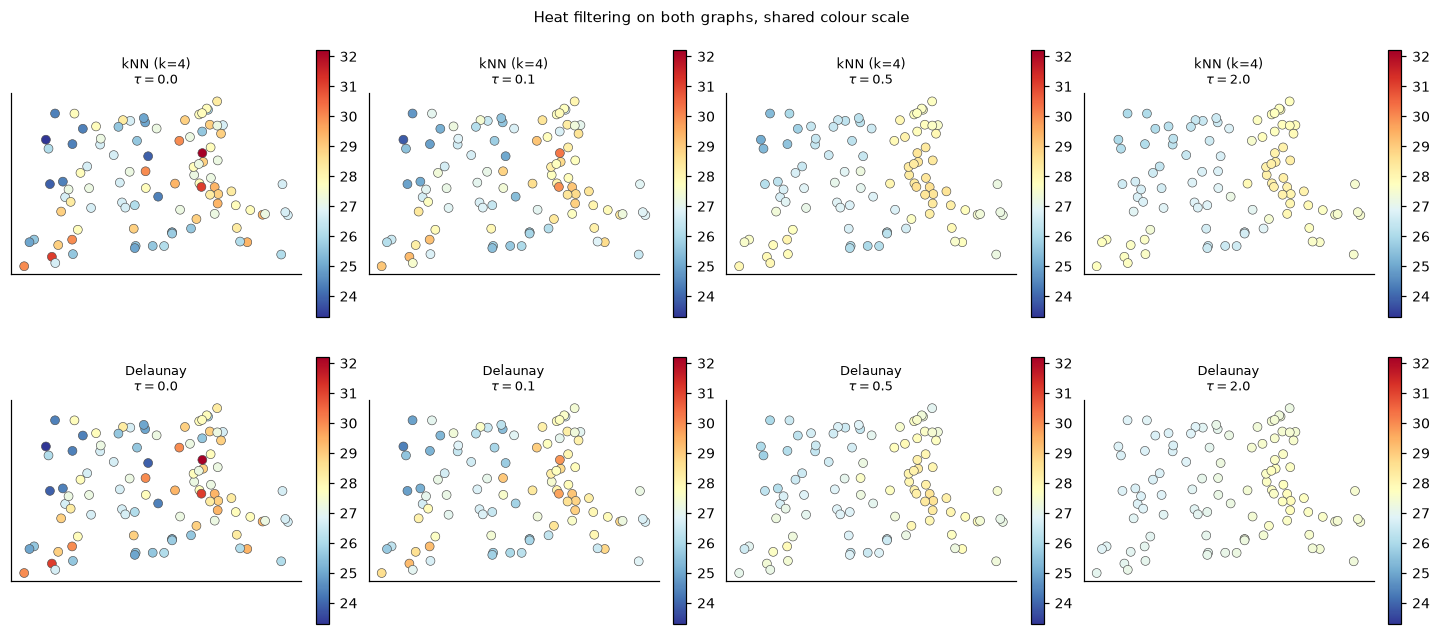

In [24]:
TAUS = [0.0, 0.1, 0.5, 2.0]
print(f"{'graph':16s}{'lam_max':>9s}" + "".join(f"{'tau=' + str(t):>12s}" for t in TAUS))
for name, op in OPS.items():
    lam, zhat = op["lam"], op["zhat"]
    retained = [100 * np.sum((np.exp(-t * lam) * zhat) ** 2) / np.sum(zhat ** 2) for t in TAUS]
    print(f"{name:16s}{lam[-1]:9.3f}" + "".join(f"{r:11.1f}%" for r in retained))
print()
print("Same tau, different attenuation: at tau=0.5 the kNN graph keeps about a quarter of")
print("the non-constant energy while Delaunay keeps a seventh. Reporting 'we smoothed with")
print("tau=0.5' is therefore not reproducible unless the graph is specified too.")

fig, axes = plt.subplots(len(OPS), len(TAUS), figsize=(13, 5.8))
for row, (name, op) in enumerate(OPS.items()):
    for col, t in enumerate(TAUS):
        y = x_bar + op["U"] @ (np.exp(-t * op["lam"]) * op["zhat"])
        sc = map_signal(axes[row, col], y, f"{name}\n$\\tau={t}$", cmap="RdYlBu_r")
        sc.set_clim(vmin, vmax)
        fig.colorbar(sc, ax=axes[row, col], fraction=0.046)
fig.suptitle("Heat filtering on both graphs, shared colour scale", fontsize=10)
plt.show()

### What could be wrong with all of this

Five caveats, each of which would change the numbers above.

1. **Irregular station density.** Stations cluster around Boston, Providence and Hartford and thin
   out in western Massachusetts. A $k$-NN graph adapts to density — edges are short where stations
   are dense — so a "mode" covers far more ground in the west than in the east. Any spatial
   interpretation of a mode is therefore non-uniform across the map.
2. **Long boundary edges.** Delaunay's convex-hull edges span up to 293 km and are weighted the same
   as a 5 km edge. They impose smoothness between stations with no physical relationship.
3. **Coastal effects.** The August land–sea temperature contrast is large, and a station 2 km inland
   can differ sharply from one on the shore. Graph edges cross that boundary freely because nothing
   in the construction knows where the coast is.
4. **Omitted elevation.** Correlation with temperature is $-0.45$ here. Two stations 10 km apart and
   300 m apart in height are near-neighbours in the graph and physically quite different.
5. **One day, one region, one element.** Nothing here generalises to other dates without repeating
   the analysis. A winter day with a frontal passage would look entirely different.

> ⚠️ **What these results are, and are not.** Everything in this section is **representation and
> smoothing of observations we already hold**. No value was withheld and predicted; no noise model
> was posited and removed. In particular, high-frequency content here is not "noise" — sea breeze
> and elevation effects are real weather, and a low-pass filter erases them exactly as it erases
> measurement error. Establishing prediction or denoising performance would require held-out
> stations, a baseline like inverse-distance or kriging, and an error metric agreed in advance. That
> is a different exercise and this notebook does not attempt it.


---
## 6. Extension: a county-contiguity graph

Stations gave us a point set, where the graph had to be invented. **Areal** data is different: when
nodes are regions, adjacency is already defined by shared boundaries, and the graph is closer to
being given.

We build a contiguity graph over the 27 counties of Connecticut, Massachusetts and Rhode Island and
attach a socioeconomic signal.

**Two data-alignment issues, both real:**

- **Vintage.** Connecticut **abolished county government for statistical purposes**: from 2022 the
  Census Bureau reports Connecticut by nine *planning regions* with new GEOIDs (`09110`–`09190`),
  replacing the eight legacy counties (`09001`–`09015`). A contiguity file built on the older
  vintage cannot be joined to a recent ACS release. We therefore pair the legacy-vintage adjacency
  file with **ACS 2019 5-year** estimates, which still use legacy counties.
- **GEOID as the join key.** County names are not unique across states and are not stable; the
  5-digit `GEOID` (2-digit state + 3-digit county) is. We join on it and check for unmatched rows
  rather than assuming the merge worked.

**Rook versus queen contiguity.** Two regions might share a boundary *segment* (rook) or meet at a
single *point* (queen). The Census adjacency file is queen-style: it lists any pair sharing
boundary points at all. Distinguishing the two requires the actual polygons from
[TIGER/Line](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)
and a geometry library, which this notebook does not require — so we use the published file and
state the convention rather than silently adopting one.


In [25]:
ADJ_URL = "https://www2.census.gov/geo/docs/reference/county_adjacency.txt"
ADJ_CACHE = os.path.join(DATA_DIR, "county_adjacency.txt")
REGION_STATE_FIPS = ("09", "25", "44")        # CT, MA, RI

if not os.path.exists(ADJ_CACHE):
    print(f"downloading {ADJ_URL} (0.73 MB, once) ...")
    urllib.request.urlretrieve(ADJ_URL, ADJ_CACHE)

# Format: tab separated, 4 fields. The county's own name/GEOID appear only on the first
# line of its block; continuation lines have those two fields blank.
county_name, adjacency = {}, set()
current = None
for line in io.open(ADJ_CACHE, encoding="latin-1"):
    if not line.strip():
        continue
    f = [c.strip().strip('"') for c in line.rstrip("\n").split("\t")]
    if len(f) < 4:
        continue
    if f[0]:
        current, county_name[f[1]] = f[1], f[0]
    county_name.setdefault(f[3], f[2])
    if current and f[3] and current != f[3]:
        adjacency.add(frozenset((current, f[3])))

region = sorted(g for g in county_name if g[:2] in REGION_STATE_FIPS)
Gc = nx.Graph()
Gc.add_nodes_from(region)
for pair in adjacency:
    a, b = tuple(pair)
    if a in region and b in region:
        Gc.add_edge(a, b)

print(f"counties parsed nationwide : {len(county_name)}")
print(f"counties in CT / MA / RI   : {len(region)}")
print(f"contiguity graph           : {Gc.number_of_nodes()} nodes, {Gc.number_of_edges()} edges, "
      f"{nx.number_connected_components(Gc)} component(s)")
degs = dict(Gc.degree())
print(f"degree range               : {min(degs.values())} to {max(degs.values())}")
print(f"islands (degree 0)         : {[county_name[g] for g in Gc if Gc.degree(g) == 0] or 'none'}")
print()
print("sample GEOID -> name:")
for g in region[:4]:
    print(f"   {g}  {county_name[g]}")

counties parsed nationwide : 3234
counties in CT / MA / RI   : 27
contiguity graph           : 27 nodes, 59 edges, 1 component(s)
degree range               : 1 to 8
islands (degree 0)         : none

sample GEOID -> name:
   09001  Fairfield County, CT
   09003  Hartford County, CT
   09005  Litchfield County, CT
   09007  Middlesex County, CT


In [26]:
# ACS median household income (table B19013_001E). The Census API now requires a free key:
#   https://api.census.gov/data/key_signup.html
# Set it in the environment as CENSUS_API_KEY. Without it we skip the SIGNAL, but the
# contiguity GRAPH above -- the part this lesson is actually about -- is already built.
CENSUS_KEY = os.environ.get("CENSUS_API_KEY", "").strip()
ACS_YEAR = 2019                               # legacy CT counties; matches the adjacency vintage
INCOME_CACHE = os.path.join(DATA_DIR, f"acs{ACS_YEAR}_b19013_ct_ma_ri.csv")

income = None
if os.path.exists(INCOME_CACHE):
    income = pd.read_csv(INCOME_CACHE, dtype={"GEOID": str})
    print(f"loaded cache: {INCOME_CACHE}")
elif CENSUS_KEY:
    url = (f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5?get=NAME,B19013_001E"
           f"&for=county:*&in=state:{','.join(REGION_STATE_FIPS)}&key={CENSUS_KEY}")
    try:
        with urllib.request.urlopen(url) as r:
            payload = json.loads(r.read().decode())
        income = pd.DataFrame(payload[1:], columns=payload[0])
        income["GEOID"] = income["state"] + income["county"]
        income["median_income"] = pd.to_numeric(income["B19013_001E"], errors="coerce")
        income = income[["GEOID", "NAME", "median_income"]]
        income.to_csv(INCOME_CACHE, index=False)
        print(f"fetched and cached {len(income)} counties -> {INCOME_CACHE}")
    except Exception as exc:
        print(f"ACS request failed ({type(exc).__name__}: {exc}); skipping the signal.")
else:
    print("No CENSUS_API_KEY set and no cache present -- skipping the ACS signal.")
    print("To run this part: request a free key at https://api.census.gov/data/key_signup.html,")
    print("set CENSUS_API_KEY in your environment, and re-run this cell.")
    print("Nothing else in the notebook depends on it.")

if income is not None:
    merged = pd.DataFrame({"GEOID": list(Gc.nodes())}).merge(income, on="GEOID", how="left")
    missing = merged["median_income"].isna().sum()
    print(f"\njoin on GEOID: {len(merged)} counties, {missing} without a value")
    if missing == 0:
        order = merged["GEOID"].tolist()
        Ac = nx.to_numpy_array(Gc, nodelist=order, weight=None)
        Lc = np.diag(Ac.sum(axis=1)) - Ac
        lam_c, Uc = np.linalg.eigh(Lc)
        y = merged["median_income"].to_numpy(float)
        zc = y - y.mean()
        yhat = Uc.T @ zc
        nulls = np.array([(p := rng.permutation(zc)) @ Lc @ p for _ in range(5000)])
        print(f"median household income: {y.min():,.0f} to {y.max():,.0f} USD")
        print(f"Dirichlet energy per edge: {zc @ Lc @ zc / Gc.number_of_edges():,.0f} USD^2")
        print(f"permutations at least as smooth: {np.mean(nulls <= zc @ Lc @ zc):.2%}")
        print(f"energy in the 4 lowest non-constant modes: "
              f"{100 * (yhat[1:5] ** 2).sum() / (yhat[1:] ** 2).sum():.1f}%")

No CENSUS_API_KEY set and no cache present -- skipping the ACS signal.
To run this part: request a free key at https://api.census.gov/data/key_signup.html,
set CENSUS_API_KEY in your environment, and re-run this cell.
Nothing else in the notebook depends on it.


### Interpretation questions

<details>
<summary><b>1.</b> Which of this notebook's conclusions depend on the data, and which depend on the
graph?</summary>

**On the data:** that the field is smoother than a random reassignment of the same temperatures
(true on both graphs, around the 1st percentile); that typical neighbouring stations differ by about
$2.2\,^\circ$C; that elevation correlates $-0.45$ with temperature; and that a two-parameter
elevation regression is competitive with several graph modes. These survive changing the
construction.

**On the graph:** every eigenvalue and eigenvector; how *strongly* the region divides ($\lambda_2$ is
0.025 against 0.293, and the same west–east cut costs 4 edges on one graph and 24 on the other); the
meaning of any coefficient $\widehat{z}_k$ beyond the first few; and the attenuation produced by a
given $\tau$. None of these transfer between constructions. The *orientation* of the leading modes —
west–east, then north–south — does transfer, which is a mild vote of confidence in the
low-frequency picture specifically.

A useful test: if you cannot state a result without naming the construction, it is a property of your
modelling choice, not of New England.
</details>

<details>
<summary><b>2.</b> What would justify preferring one construction over the other?</summary>

An external criterion, decided before looking at the answer. Candidates, in rough order of strength:
**held-out predictive accuracy** (mask stations, reconstruct, measure error — the honest version of
"which graph represents this field better"); **physical defensibility** (do the edges connect places
that actually exchange air? the 293 km Delaunay boundary edges plainly do not); **stability** (does
the result survive dropping 10% of stations, or moving to the next day?); and **parameter economy**
(Delaunay has no $k$ to tune, which is a real advantage if you cannot justify a particular $k$).

What does *not* justify a choice is picking whichever construction makes the signal look smoothest.
That is selecting on the outcome, and it guarantees a flattering answer regardless of the truth.
</details>

<details>
<summary><b>3.</b> A colleague reports "we smoothed the field with $\tau = 0.5$". What do you need
before you can reproduce it?</summary>

The full graph construction: which stations, which projection, $k$-NN or Delaunay, which $k$, how
ties and coincident points were handled, and whether the graph was weighted. $\tau$ multiplies
eigenvalues, and eigenvalue scale is set by the edge set — Section 5 shows $\tau=0.5$ retaining 25%
of non-constant energy on one graph and 14% on the other. $\tau$ is not a smoothing radius in
kilometres and does not transfer between graphs, datasets, or even between two days if stations drop
in and out.
</details>

<details>
<summary><b>4.</b> Why not just use latitude and longitude directly as the coordinates for $k$-NN?</summary>

Because a degree of longitude is about 82 km at this latitude while a degree of latitude is about
111 km, so unprojected Euclidean distance silently stretches the map north–south by roughly 35%.
That changes which stations are nearest and therefore rewires the graph — Section 3 demonstrates
exactly this failure with a deliberate anisotropic stretch. Projecting first, with a documented CRS
whose distortion you have measured, removes the problem.
</details>

<details>
<summary><b>5.</b> The reconstruction RMSE keeps falling as $K$ grows and reaches zero at $K=n$.
Does that show the graph representation is good?</summary>

No. At $K=n$ the basis is complete and reproduces *any* vector exactly, graph or no graph — including
pure noise. Monotone decreasing error is a property of orthonormal expansion, not evidence about the
signal. The informative questions are how *fast* the error falls (here: slowly), how it compares to
graph-free baselines at matching parameter counts (here: unfavourably against elevation), and how it
behaves on data withheld from the fit (here: not tested).
</details>

<details>
<summary><b>6.</b> Delaunay's $\lambda_2$ is ten times larger than $k$-NN's. Is the Delaunay graph
"better connected", and is that good?</summary>

Better connected, yes — that is what a large algebraic connectivity means, and it happens because the
convex-hull edges stitch the region's extremities together. Whether it is *good* is a different
question. Both graphs agree the principal division is west–east; they disagree on its price, 4 edges
against 24, and Delaunay's extra 20 include edges up to 293 km long that assert smoothness between
places with no physical relationship. The $k$-NN graph's tiny $\lambda_2$ is arguably the more
faithful report: western Connecticut really is weakly coupled to Cape Cod. A spectral quantity being
larger is not a quality score.
</details>

### Correctness checks


In [27]:
tol = 1e-9
checks = []
def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# --- alignment between metadata, signal and matrices ---------------------------
check("station order is unique and canonical",
      len(station_ids) == len(set(station_ids)) == n)
check("obs rows align with the station order",
      obs["station"].tolist() == station_ids)
check("positions and signal have matching length",
      Ppos.shape == (n, 2) and x.shape == (n,) and elev.shape == (n,))
check("all coordinates and signals are finite",
      np.all(np.isfinite(Ppos)) and np.all(np.isfinite(x)) and np.all(np.isfinite(elev)))
check("no coincident stations remain",
      len({(a, b) for a, b in zip(obs['lat'], obs['lon'])}) == n)
check("temperatures are physically plausible for a summer day",
      float(x.min()) > -50 and float(x.max()) < 60, f"{x.min():.1f} to {x.max():.1f} degC")
check("no -9999 sentinel survived into the signal", not np.any(np.isclose(x, -999.9)))

# --- distance matrix -----------------------------------------------------------
check("Dphys symmetric with zero diagonal",
      np.allclose(Dphys, Dphys.T) and np.allclose(np.diag(Dphys), 0))
# Recomputed here against the FINAL station set, since `pairs` above was built
# before de-duplication and its indices no longer refer to the same stations.
chk_pairs = [(a, b) for a in range(0, n, 3) for b in range(a + 1, n, 5)]
chk_geo = np.array([geod.inv(obs['lon'][a], obs['lat'][a],
                             obs['lon'][b], obs['lat'][b])[2] for a, b in chk_pairs])
chk_planar = np.array([np.hypot(Ppos[a, 0] - Ppos[b, 0], Ppos[a, 1] - Ppos[b, 1])
                       for a, b in chk_pairs])
chk_rel = float(np.max(np.abs(chk_planar - chk_geo) / np.maximum(chk_geo, 1.0)))
check("projection distortion below 0.05% across the region", chk_rel < 5e-4,
      f"max {chk_rel * 100:.4f}%")

# --- both graphs ---------------------------------------------------------------
for name, op in OPS.items():
    A, L, lam, U = op["A"], op["L"], op["lam"], op["U"]
    check(f"[{name}] A symmetric, binary, zero diagonal",
          np.allclose(A, A.T) and set(np.unique(A)) <= {0.0, 1.0} and np.allclose(np.diag(A), 0))
    check(f"[{name}] L = D - A and L @ 1 == 0",
          np.allclose(L, np.diag(A.sum(axis=1)) - A) and np.abs(L @ np.ones(n)).max() < tol)
    check(f"[{name}] connected: exactly one zero eigenvalue",
          int(np.sum(np.abs(lam) < 1e-8)) == nx.number_connected_components(op["g"]) == 1)
    check(f"[{name}] eigenpair residual",
          max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(n)) < 1e-9,
          f"{max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(n)):.2e}")
    check(f"[{name}] U orthonormal", np.abs(U.T @ U - np.eye(n)).max() < 1e-9,
          f"{np.abs(U.T @ U - np.eye(n)).max():.2e}")
    check(f"[{name}] GFT inversion exact",
          np.abs(U @ (U.T @ z) - z).max() < 1e-9, f"{np.abs(U @ (U.T @ z) - z).max():.2e}")
    check(f"[{name}] Parseval on the centred signal",
          np.isclose(z @ z, (op['zhat'] ** 2).sum()),
          f"{z @ z:.6f} vs {(op['zhat'] ** 2).sum():.6f}")
    check(f"[{name}] Dirichlet: matrix == edge == spectral form",
          np.isclose(z @ L @ z, sum((z[a] - z[b]) ** 2 for a, b in op["g"].edges()))
          and np.isclose(z @ L @ z, float((lam * op['zhat'] ** 2).sum())))
    check(f"[{name}] truncation error equals discarded energy",
          all(np.isclose(np.linalg.norm(z - U[:, :K] @ (U.T @ z)[:K]) ** 2,
                         ((U.T @ z)[K:] ** 2).sum()) for K in (1, 5, 20, 60)))
    check(f"[{name}] reconstruction is exact at K = n",
          np.abs(reconstruct(op, n) - x).max() < 1e-9)
    check(f"[{name}] RMSE decreases monotonically in K",
          np.all(np.diff(op["rmse_curve"]) <= 1e-12))
    check(f"[{name}] signal smoother than chance", op["null_pct"] < 0.05,
          f"p = {op['null_pct']:.4f}")

# --- graph construction used geometry only -------------------------------------
check("kNN degrees are at least k (symmetrisation can only add edges)",
      min(dg for _, dg in OPS[f"kNN (k={K_NN})"]["g"].degree()) >= K_NN)
check("K_NN is the SMALLEST connected k",
      nx.number_connected_components(knn_graph(K_NN)) == 1
      and nx.number_connected_components(knn_graph(K_NN - 1)) > 1)
check("the two constructions genuinely differ",
      set(map(frozenset, OPS[f"kNN (k={K_NN})"]["g"].edges()))
      != set(map(frozenset, OPS["Delaunay"]["g"].edges())))
check("Delaunay carries edges far longer than kNN's longest",
      edge_lengths["Delaunay"].max() > 2 * edge_lengths[f"kNN (k={K_NN})"].max(),
      f"{edge_lengths['Delaunay'].max():.0f} km vs {edge_lengths[f'kNN (k={K_NN})'].max():.0f} km")
check("GFT is unchanged when coordinates move but L is held fixed",
      np.allclose(OPS[f"kNN (k={K_NN})"]["U"].T @ z, zhat_knn_ref),
      f"max diff {np.abs(OPS[f'kNN (k={K_NN})']['U'].T @ z - zhat_knn_ref).max():.2e}")

# --- the county extension ------------------------------------------------------
check("county graph: 27 counties, connected, no isolates",
      Gc.number_of_nodes() == 27 and nx.number_connected_components(Gc) == 1
      and min(dict(Gc.degree()).values()) > 0)
check("county GEOIDs are 5 digits from the three target states",
      all(len(g) == 5 and g[:2] in REGION_STATE_FIPS for g in Gc.nodes()))

# --- report --------------------------------------------------------------------
width = max(len(nm) for nm, _, _ in checks)
for nm, ok, detail in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {nm:<{width}}  {detail}")
failed = [nm for nm, ok, _ in checks if not ok]
assert not failed, f"failed checks: {failed}"
print(f"\nAll {len(checks)} checks passed.")

PASS  station order is unique and canonical                           
PASS  obs rows align with the station order                           
PASS  positions and signal have matching length                       
PASS  all coordinates and signals are finite                          
PASS  no coincident stations remain                                   
PASS  temperatures are physically plausible for a summer day          23.3 to 32.2 degC
PASS  no -9999 sentinel survived into the signal                      
PASS  Dphys symmetric with zero diagonal                              
PASS  projection distortion below 0.05% across the region             max 0.0100%
PASS  [kNN (k=4)] A symmetric, binary, zero diagonal                  
PASS  [kNN (k=4)] L = D - A and L @ 1 == 0                            
PASS  [kNN (k=4)] connected: exactly one zero eigenvalue              
PASS  [kNN (k=4)] eigenpair residual                                  6.11e-15
PASS  [kNN (k=4)] U orthonormal          

---
## Applied conclusion

**The question was whether geographic relationships give a compact representation of regional
temperature, and how sensitive that representation is to graph construction. The answers are "only
weakly" and "very".**

*What we established.* On 2015-08-06, daily maximum temperature across 97 stations in southern New
England is measurably smoother on both coordinate-derived graphs than a random reassignment of the
same temperatures would be — about the 1st percentile in each case. Connected stations differ by
roughly $2.2\,^\circ$C against $2.4\,^\circ$C under permutation. Geography is carrying real
information.

*What we could not establish.* That this makes a useful representation. Half the non-constant energy
needs tens of modes; a two-parameter regression on elevation — which the graph never sees — matches
about half a dozen graph modes; and the residual maps stay patchy. The graph basis is not obviously
the right tool for this particular field.

*What depended on us rather than on the weather.* Nearly every spectral quantity. The two
constructions differ by a factor of twelve in $\lambda_2$, price the same west–east cut at 4 edges
against 24, lose mode-to-mode eigenvector correspondence entirely above about $k=10$, and attenuate
differently at the same $\tau$. Only basis-free quantities — energy, per-edge Dirichlet energy, RMSE at a given $K$ —
survived the change of construction.

*Transferable practice.* Keep positions $p_i$ and signal $x_i$ notationally distinct. Project before
measuring distance and measure the distortion. Build the graph from geometry alone, never from the
signal. Choose construction parameters by a stated rule, not by the answer. Normalise Dirichlet
energy per edge before comparing graphs with different edge counts. Calibrate smoothness against a
permutation null. And report every spectral quantity together with the construction that produced it
— on spatial data, a coefficient without its graph is not a result.

### References collected

- **[GHCN-Daily readme](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt)** — record layout,
  element units (tenths of °C for `TMAX`), the `-9999` sentinel, and the full quality-flag table.
  The filters in Section 1 come straight from it.
- **[von Luxburg, *A Tutorial on Spectral Clustering* (2007)](https://arxiv.org/abs/0711.0189)** —
  Section 2.2 on neighbourhood-graph construction ($\varepsilon$-ball, $k$-NN, mutual $k$-NN) and
  Section 8 on how uneven sampling density interacts with the choice.
- **[`scipy.spatial.Delaunay`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)**
  — the triangulation, its `simplices` output, and the convex-hull property responsible for the long
  boundary edges.
- **[Shuman et al., *The Emerging Field of Signal Processing on Graphs*
  (2013)](https://arxiv.org/abs/1211.0053)** — graph frequency on irregular domains; Section V-A
  covers the distance-based edge weighting deferred to the next lesson.
- **[Census county adjacency file](https://www2.census.gov/geo/docs/reference/county_adjacency.txt)**
  and **[TIGER/Line](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)**
  — areal contiguity; TIGER/Line polygons would be needed to separate rook from queen adjacency.
- **[ACS 5-year estimates](https://www.census.gov/data/developers/data-sets/acs-5year.html)** —
  table `B19013_001E`, median household income. The API requires a free key.

> **What is demonstrated where.** The transform identities used here — Parseval, the two forms of the
> Dirichlet energy, the truncation-error formula, the heat-kernel response — are standard results
> developed in Shuman et al.; the neighbourhood-graph constructions and their behaviour under uneven
> density are from von Luxburg. The specific analyses in this notebook are **exercises built for this
> lesson**: the two-construction comparison on GHCN stations, the permutation null, the elevation and
> planar-trend baselines, the coordinate-transformation demonstration, and the $\tau$-portability
> comparison are not results reported in those papers.

### Where to go next

The recurring limitation in this lesson was the unweighted edge: a 5 km link and a 293 km link are
charged identically. The next lesson takes that up directly, replacing $A$ with a weight matrix $W$
and asking how a distance becomes an affinity — a conversion that is far less obvious than it looks,
and which changes the frequency axis along with everything built on it.
